
# run_old_Angle_range — single protein

This notebook is a **diagnostic comparison version** for the old-run dataset.

It keeps the same geometrical workflow:

**aligned protein → real MSMS 3D surface → orthographic visibility → normal-angle selection → tunnel-connected frontal face → geometric core**

The important difference is that it does **not ask you to choose one angle immediately**.

It calculates and displays four fixed frontal-angle hypotheses:

\[
20^\circ,\quad 40^\circ,\quad 60^\circ,\quad 80^\circ
\]

and three fixed core-depth hypotheses:

\[
4\ \AA,\quad 5\ \AA,\quad 6\ \AA
\]

The purpose is to compare the resulting regions visually before selecting a final parameter.

The old-run tunnel coordinate file is expected in the format:

```text
Index,Protein_name,X,Y,Z
```



## Step 1 — What geometrical question are we solving?

### Spiegazione italiana

La proteina è già stata allineata in modo che il vettore **centroide → uscita del tunnel** punti sempre nella stessa direzione. Chiamiamo questa direzione unitaria **v**.

Ogni piccolo triangolo della superficie molecolare possiede una normale esterna **n**.

L'angolo \(\theta\) tra la normale e la direzione frontale ci dice quanto quel piccolo pezzo di superficie è inclinato rispetto alla superficie solida che immaginiamo davanti all'enzima.

Matematicamente:

\[
\cos(\theta)=\mathbf n\cdot\mathbf v
\]

perché sia **n** sia **v** vengono normalizzati a lunghezza 1.

La nuova versione del metodo introduce un parametro modificabile:

\[
\theta_{\max}=\texttt{FRONTAL\_ANGLE\_DEG}
\]

e considera sufficientemente front-facing un triangolo quando:

\[
\theta\le\theta_{\max}
\]

che è equivalente a:

\[
\mathbf n\cdot\mathbf v
\ge
\cos(\theta_{\max})
\]

Esempi:

- `90°` → \(\cos90^\circ=0\): recupera praticamente la definizione geometrica originale \(n\cdot v>0\), cioè tutto l'emisfero orientato verso il substrato;
- `70°` → \(\cos70^\circ\approx0.342\): esclude la parte più inclinata verso il lato;
- `60°` → \(\cos60^\circ=0.5\): mantiene una regione frontale più restrittiva.

Questa soglia **non dice che a 61° o 71° la superficie smette fisicamente di interagire**. Serve soltanto a definire in modo controllabile quanto vogliamo essere severi nel chiamare una regione "frontal face".

La proteina può però avere cavità, loop e sovrapposizioni. Per questo l'angolo non basta: manteniamo anche il controllo di **visibilità ortografica** con la depth map.

Infine conserviamo soltanto la componente connessa alla direzione centrale del tunnel.

La definizione operativa diventa:

\[
\text{Frontal face}_{\theta_{\max}}
=
\text{visible}
\cap
(\theta\le\theta_{\max})
\cap
\text{connected to the tunnel region}
\]

### English explanation

The protein has already been aligned so that the **centroid → tunnel-exit** vector points in the same direction for every protein. We call this unit direction **v**.

Each molecular-surface triangle has an outward normal vector **n**.

The angle \(\theta\) between the normal and the frontal direction measures how strongly that local surface element is tilted away from the substrate-facing direction.

Because **n** and **v** are unit vectors:

\[
\cos(\theta)=\mathbf n\cdot\mathbf v
\]

This notebook introduces an adjustable parameter:

\[
\theta_{\max}=\texttt{FRONTAL\_ANGLE\_DEG}
\]

A triangle is considered sufficiently front-facing when:

\[
\theta\le\theta_{\max}
\]

equivalently:

\[
\mathbf n\cdot\mathbf v
\ge
\cos(\theta_{\max})
\]

Examples:

- `90°` → approximately recovers the original geometrical \(n\cdot v>0\) definition;
- `70°` → excludes the most strongly tilted lateral surface;
- `60°` → defines a more restrictive frontal region.

The cutoff does **not** imply that interactions abruptly disappear outside that angle. It is only a controllable geometrical definition of how restrictive the frontal face should be.

Visibility from the tunnel direction is still required, and only the component connected to the central tunnel direction is retained.

Thus:

\[
\text{Frontal face}_{\theta_{\max}}
=
\text{visible}
\cap
(\theta\le\theta_{\max})
\cap
\text{connected to the tunnel region}
\]


In [1]:

from pathlib import Path
from collections import defaultdict, deque
import math
import re
import warnings
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from IPython.display import display

try:
    import plotly.graph_objects as go
except ImportError as exc:
    raise ImportError("Install plotly with: %pip install plotly") from exc

try:
    import ipywidgets as widgets
except ImportError as exc:
    raise ImportError("Install ipywidgets with: %pip install ipywidgets") from exc

try:
    from numba import njit
except ImportError as exc:
    raise ImportError("Install numba with: %pip install numba") from exc



## Step 2 — The two independent parameters: frontal angle and core depth

### Spiegazione italiana

La **frontal-face boundary** dipende dal valore scelto di `FRONTAL_ANGLE_DEG`, mentre la profondità del core viene applicata soltanto dopo. I due parametri sono indipendenti.

Solo dopo aver trovato la faccia frontale definiamo una regione più stretta che chiamiamo **geometric core**.

Immaginiamo un piano solido perfettamente piano che si avvicina alla proteina lungo **v**. Il primo punto della faccia frontale che il piano incontra definisce il **first-contact plane**.

Per ogni punto \(P_i\) della faccia frontale calcoliamo la sua coordinata lungo l'asse:

\[
d_i = P_i\cdot\mathbf{v}
\]

Il punto più avanzato ha:

\[
d_{contact} = \max(d_i)
\]

La profondità di ciascun punto rispetto al primo contatto è:

\[
h_i=d_{contact}-d_i
\]

Quindi:

- \(h=0\) Å significa che il punto appartiene alla parte più avanzata;
- \(h=4\) Å significa che è arretrato di 4 Å lungo la direzione perpendicolare alla superficie;
- \(h=6\) Å significa che è arretrato di 6 Å.

Il core è semplicemente:

\[
\text{Core}=\{P_i\in\text{Frontal face}: h_i\le D_{core}\}
\]

`CORE_DEPTH_A` è il cutoff di profondità del core. `FRONTAL_ANGLE_DEG` è invece il cutoff geometrico che determina quanto la frontal face viene ristretta rispetto alla definizione a 90°. Il valore iniziale è 5 Å, circa la scala di profondità di un singolo residuo, ma puoi cambiarlo direttamente a 4, 5, 6 Å o a qualsiasi valore che vorrai testare.

Questo cutoff **non significa** che un'interazione elettrostatica oltre quella distanza sia nulla. Serve soltanto a costruire il core geometrico iniziale. L'estensione chimicamente rilevante verrà aggiunta in uno step successivo e non potrà superare la frontal-face boundary.

### English explanation

The **frontal-face boundary** depends on `FRONTAL_ANGLE_DEG`, whereas core depth is applied only afterwards. These are independent parameters.

Only after the frontal face has been identified do we define a narrower **geometric core**.

Imagine a perfectly planar solid surface approaching the protein along **v**. The most advanced point of the frontal face defines the **first-contact plane**.

For each frontal-surface point \(P_i\):

\[
d_i=P_i\cdot\mathbf{v}
\]

The most advanced position is:

\[
d_{contact}=\max(d_i)
\]

The depth behind that plane is:

\[
h_i=d_{contact}-d_i
\]

The geometric core is:

\[
\text{Core}=\{P_i\in\text{Frontal face}: h_i\le D_{core}\}
\]

`CORE_DEPTH_A` controls core depth, while `FRONTAL_ANGLE_DEG` controls how restrictive the frontal-face definition is. It starts at 5 Å but can be changed directly.

This cutoff does **not** imply that electrostatic interactions vanish beyond that distance. It is only the initial geometrical core. A chemically relevant extension can be added later, while remaining inside the frontal-face boundary.


In [2]:

# =============================================================================
# USER PATHS
# =============================================================================

# Aligned PDB produced by the proteinAlign workflow.
ALIGNED_PDB_PATH = Path(
    r"/home/chiara/Desktop/COMENZE/Comenze_pipeline/enzymes_Review/pdb_files/pdb_aligned/1CEX_cutfv_4rev_aligned.pdb"
)

# Directory containing the SURFMAP/MSMS files generated from THIS aligned protein.
# The notebook will try to find .vert, .face, *_shell.pdb and *_coord_list.txt.
SURFMAP_DIR = Path(
    r"/home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/surfmap/rad0.5_s2_nosmooth/output_SURFMAP_1CEX_cutfv_4rev_aligned_bfactor"
)

# Optional explicit files. Leave as None to auto-detect them in SURFMAP_DIR.
MSMS_VERT_FILE = None
MSMS_FACE_FILE = None
SHELL_PDB_FILE = None
COORD_LIST_FILE = None

# OLD RUN CSV FORMAT: protein,tunnel_xyz
# Example: 1CEX_cutfv,"[13.636571,50.498968,14.826886]"
# This file is REQUIRED in the old_run notebooks.
# Tunnel-coordinate table.
# It is read for traceability, but the aligned tunnel direction itself is already
# fixed by proteinAlign and therefore does not require a second scientific parameter.
TUNNEL_COORDS_FILE = Path(
    r"/home/chiara/Desktop/COMENZE/Comenze_pipeline/enzymes_Review/pdb_files/pdb_aligned_old/tunnelsCoords_old.csv"
)

# Root directory selected by the user.
# A protein-specific subfolder will be created automatically inside it.
OUTPUT_DIR = Path(
    r"/home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/SURFMAP_VALIDATION/SURFMAP_ROI"
)

# =============================================================================
# COMPARISON PARAMETERS
# =============================================================================

# Four frontal-angle hypotheses shown simultaneously.
ANGLE_CUTOFFS_DEG = [20.0, 40.0, 60.0, 80.0]

# Different colors are intentionally used to make the four hypotheses
# visually distinguishable.
ANGLE_COLORS = {
    20.0: "#E69F00",
    40.0: "#56B4E9",
    60.0: "#009E73",
    80.0: "#CC79A7",
}

# Default angle used only by the single interactive 3D view.
# Change this freely after inspecting the four comparison panels.
FRONTAL_ANGLE_DEG = 60.0

# Three initial geometric-core depths shown simultaneously.
CORE_DEPTHS_A = [4.0, 5.0, 6.0]

CORE_COLORS = {
    4.0: "#D55E00",
    5.0: "#0072B2",
    6.0: "#009E73",
}

# Default depth used only by the single interactive core view and exports.
CORE_DEPTH_A = 5.0

# Exact common axis used by proteinAlign:
TARGET_AXIS = np.array([-25.77, 1.56, -0.93], dtype=float)
TARGET_AXIS = TARGET_AXIS / np.linalg.norm(TARGET_AXIS)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Run type: OLD RUN")
print("Aligned PDB:", ALIGNED_PDB_PATH)
print("SURFMAP directory:", SURFMAP_DIR)
print("Angle comparison:", ANGLE_CUTOFFS_DEG, "degrees")
print("Interactive default angle:", FRONTAL_ANGLE_DEG, "degrees")
print("Core-depth comparison:", CORE_DEPTHS_A, "Å")
print("Interactive/export default core:", CORE_DEPTH_A, "Å")
print("Target axis:", TARGET_AXIS)


Run type: OLD RUN
Aligned PDB: /home/chiara/Desktop/COMENZE/Comenze_pipeline/enzymes_Review/pdb_files/pdb_aligned/1CEX_cutfv_4rev_aligned.pdb
SURFMAP directory: /home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/surfmap/rad0.5_s2_nosmooth/output_SURFMAP_1CEX_cutfv_4rev_aligned_bfactor
Angle comparison: [20.0, 40.0, 60.0, 80.0] degrees
Interactive default angle: 60.0 degrees
Core-depth comparison: [4.0, 5.0, 6.0] Å
Interactive/export default core: 5.0 Å
Target axis: [-0.99752575  0.06038573 -0.03599918]



## Step 2A — OLD RUN tunnel coordinates: read `protein, tunnel_xyz`

### Spiegazione italiana

Il file delle coordinate del tunnel usato in questo **old run** ha il formato:

```text
protein,tunnel_xyz
1CEX_cutfv,"[13.636571,50.498968,14.826886]"
1CRL_lipCr,"[70.274194,51.186448,-8.331721]"
...
```

Il nome della proteina è contenuto nella colonna:

```text
protein
```

mentre le tre coordinate cartesiane sono contenute in una singola colonna:

```text
tunnel_xyz
```

nella forma:

\[
[x,y,z]
\]

Il notebook:

1. legge `protein`;
2. legge `tunnel_xyz`;
3. converte `[x,y,z]` in tre valori numerici \(X,Y,Z\);
4. cerca la proteina corrispondente al PDB/SURFMAP selezionato;
5. salva la coordinata come:

\[
T=(X,Y,Z)
\]

Il matching continua a tollerare i normali suffissi del workflow, per esempio:

- `_aligned`
- `_4rev`
- `_4rev_aligned`
- `_bfactor`
- `_4rev_aligned_bfactor`

Questa modifica riguarda **solo la lettura del file delle coordinate del tunnel**.

La geometria della frontal face, la visibilità ortografica, i cutoff 20°/40°/60°/80°, la connettività e i core 4/5/6 Å rimangono esattamente invariati.

### English explanation

The old-run tunnel coordinate file uses:

```text
protein,tunnel_xyz
1CEX_cutfv,"[13.636571,50.498968,14.826886]"
1CRL_lipCr,"[70.274194,51.186448,-8.331721]"
...
```

The protein identifier is stored in `protein`.

The three Cartesian tunnel coordinates are stored in `tunnel_xyz` as:

\[
[x,y,z]
\]

The notebook reads these two columns, converts the coordinate triplet to numerical \(X,Y,Z\) values, and matches the selected protein using the same workflow-name normalization used previously.

Only CSV parsing is changed. All scientific calculations remain unchanged.


In [3]:

def normalize_protein_name(name):
    """
    Normalize names only for matching workflow filenames to the
    `protein` column in the old-run tunnel coordinate CSV.

    Scientific coordinates are never modified here.
    """
    text = Path(str(name)).stem.strip()

    suffixes = [
        "_4rev_aligned_bfactor",
        "_aligned_bfactor",
        "_4rev_aligned",
        "_bfactor",
        "_aligned",
        "_4rev",
        "_shell",
        "_coord_list",
    ]

    changed = True

    while changed:
        changed = False
        lower = text.lower()

        for suffix in suffixes:
            if lower.endswith(suffix.lower()):
                text = text[:-len(suffix)]
                changed = True
                break

    return re.sub(
        r"[^a-zA-Z0-9]+",
        "",
        text,
    ).lower()


def parse_tunnel_xyz(value, row_number=None, protein=None):
    """
    Convert a tunnel_xyz value into a numerical [x, y, z] array.

    Accepted examples:
        [1.2, -3.4, 5.6]
        "[1.2,-3.4,5.6]"
        (1.2, -3.4, 5.6)

    A regex fallback is included for slightly non-standard text formatting.
    """
    import ast as _ast

    text = str(value).strip()

    # --------------------------------------------------------------
    # Primary parser: Python-like list/tuple representation
    # --------------------------------------------------------------
    try:
        xyz = np.asarray(
            _ast.literal_eval(text),
            dtype=float,
        )
    except Exception:
        xyz = None

    # --------------------------------------------------------------
    # Fallback: extract exactly three floating-point numbers
    # --------------------------------------------------------------
    if xyz is None or xyz.shape != (3,):
        number_pattern = (
            r"[-+]?(?:\d+(?:\.\d*)?|\.\d+)"
            r"(?:[eE][-+]?\d+)?"
        )

        numbers = re.findall(
            number_pattern,
            text,
        )

        if len(numbers) == 3:
            xyz = np.asarray(
                [float(x) for x in numbers],
                dtype=float,
            )
        else:
            location = ""
            if row_number is not None:
                location += f" at data row {row_number}"
            if protein is not None:
                location += f" for protein {protein!r}"

            raise ValueError(
                "Invalid tunnel_xyz value"
                f"{location}:\n"
                f"  {text!r}\n\n"
                "Expected exactly three coordinates, for example:\n"
                '  "[13.636571,50.498968,14.826886]"'
            )

    if xyz.shape != (3,):
        raise ValueError(
            "tunnel_xyz must contain exactly three coordinates.\n"
            f"Received: {text!r}"
        )

    if not np.isfinite(xyz).all():
        raise ValueError(
            "tunnel_xyz contains non-finite coordinates.\n"
            f"Received: {text!r}"
        )

    return xyz


def read_old_run_tunnel_coords_csv(path):
    """
    Read the OLD RUN format:

        protein,tunnel_xyz
        1CEX_cutfv,"[13.636571,50.498968,14.826886]"
    """
    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(
            "Old-run tunnel coordinate CSV not found:\n"
            f"{path}"
        )

    try:
        df = pd.read_csv(
            path,
            encoding="utf-8-sig",
        )
    except Exception as exc:
        raise ValueError(
            "The old-run tunnel coordinate CSV could not be read:\n"
            f"{path}"
        ) from exc

    column_lookup = {
        str(column).strip().lower(): column
        for column in df.columns
    }

    required = {
        "protein",
        "tunnel_xyz",
    }

    if not required.issubset(column_lookup):
        raise ValueError(
            "Unsupported old-run tunnel coordinate format.\n\n"
            "Expected columns:\n"
            "  protein, tunnel_xyz\n\n"
            f"Columns actually found:\n  {list(df.columns)}"
        )

    protein_col = column_lookup["protein"]
    xyz_col = column_lookup["tunnel_xyz"]

    rows = []

    for row_number, row in df.iterrows():

        protein = str(
            row[protein_col]
        ).strip()

        xyz = parse_tunnel_xyz(
            row[xyz_col],
            row_number=row_number + 2,
            protein=protein,
        )

        rows.append({
            "protein": protein,
            "x": float(xyz[0]),
            "y": float(xyz[1]),
            "z": float(xyz[2]),
        })

    table = pd.DataFrame(rows)

    if table.empty:
        raise ValueError(
            "The old-run tunnel coordinate file was read successfully, "
            "but it contains no coordinate rows."
        )

    print(
        "Detected tunnel-coordinate format: "
        "protein, tunnel_xyz"
    )
    print(
        "Coordinate rows successfully parsed:",
        len(table),
    )

    return table


def find_old_run_tunnel_record(table, pdb_path):
    """
    Match the selected workflow protein to the `protein` field.

    Exact matching is tried first.
    Normalized matching is used second.
    """
    pdb_stem = Path(pdb_path).stem

    exact_candidates = [
        pdb_stem,
        pdb_stem.replace("_4rev_aligned_bfactor", ""),
        pdb_stem.replace("_aligned_bfactor", ""),
        pdb_stem.replace("_4rev_aligned", ""),
        pdb_stem.replace("_bfactor", ""),
        pdb_stem.replace("_aligned", ""),
        pdb_stem.replace("_4rev", ""),
    ]

    # --------------------------------------------------------------
    # Exact matching first
    # --------------------------------------------------------------
    for candidate in exact_candidates:

        exact = table[
            table["protein"].astype(str) == candidate
        ]

        if len(exact) == 1:
            return exact.iloc[0]

        if len(exact) > 1:
            raise ValueError(
                "More than one exact tunnel-coordinate match "
                f"was found for {candidate!r}"
            )

    # --------------------------------------------------------------
    # Normalized matching second
    # --------------------------------------------------------------
    wanted = normalize_protein_name(
        pdb_stem
    )

    normalized = table[
        table["protein"].map(
            normalize_protein_name
        ) == wanted
    ]

    if len(normalized) == 1:
        return normalized.iloc[0]

    if len(normalized) > 1:

        names = ", ".join(
            normalized["protein"]
            .astype(str)
            .tolist()
        )

        raise ValueError(
            "Ambiguous normalized tunnel-coordinate match.\n"
            f"Selected protein: {pdb_stem}\n"
            f"Candidates: {names}"
        )

    available = ", ".join(
        table["protein"]
        .astype(str)
        .head(25)
        .tolist()
    )

    raise ValueError(
        "Protein not found in the old-run tunnel coordinate file.\n"
        f"Selected protein: {pdb_stem}\n"
        f"Available protein values (first 25): {available}"
    )


old_tunnel_table = read_old_run_tunnel_coords_csv(
    TUNNEL_COORDS_FILE
)

old_tunnel_record = find_old_run_tunnel_record(
    old_tunnel_table,
    ALIGNED_PDB_PATH,
)

TUNNEL_COORD_OLD_RUN = old_tunnel_record[
    ["x", "y", "z"]
].to_numpy(
    dtype=float
)

print("=" * 78)
print("OLD RUN TUNNEL COORDINATE")
print("=" * 78)
print(
    "Matched protein:",
    old_tunnel_record["protein"],
)
print(
    "Tunnel X,Y,Z:",
    np.array2string(
        TUNNEL_COORD_OLD_RUN,
        precision=6,
        separator=", ",
    ),
)
print(
    "Coordinate source:",
    TUNNEL_COORDS_FILE,
)
print(
    "The geometrical viewing direction remains TARGET_AXIS."
)


Detected tunnel-coordinate format: protein, tunnel_xyz
Coordinate rows successfully parsed: 42
OLD RUN TUNNEL COORDINATE
Matched protein: 1CEX_cutfv_4rev
Tunnel X,Y,Z: [13.636571, 50.498968, 14.826886]
Coordinate source: /home/chiara/Desktop/COMENZE/Comenze_pipeline/enzymes_Review/pdb_files/pdb_aligned_old/tunnelsCoords_old.csv
The geometrical viewing direction remains TARGET_AXIS.



### Automatic protein-specific output folder

The scientific calculation is unchanged.

For file organization only, the notebook now creates one subfolder inside `OUTPUT_DIR` using:

\[
\texttt{Protein\_name\_rad\_s}
\]

For example:

```text
1CEX_cutfv_rad0.5_s2
```

- `Protein_name` is taken from the matched row of the old-run tunnel-coordinate CSV.
- `rad` and `s` are read automatically from the SURFMAP run path, for example `rad0.5_s2_nosmooth`.
- All CSV files and all exported figures are written inside this protein-specific folder.

Plot titles, axes and legends used in exported figures are in English.


In [4]:

def infer_rad_s_labels(path):
    """
    Infer rad and s directly from the SURFMAP input path.

    Example:
        .../rad0.5_s2_nosmooth/output_SURFMAP_...
    returns:
        rad0.5, s2
    """
    path = Path(path)

    candidates = [
        path.name,
        path.parent.name,
        str(path),
    ]

    for text in candidates:
        match = re.search(
            r"(rad[^/\\_]+)_(s[^/\\_]+)",
            str(text),
            flags=re.IGNORECASE,
        )
        if match:
            return match.group(1), match.group(2)

    raise ValueError(
        "Could not infer rad and s from SURFMAP_DIR.\n"
        "Expected a path containing a component such as:\n"
        "  rad0.5_s2_nosmooth\n"
        f"Received:\n  {path}"
    )


def safe_output_name(text):
    text = str(text).strip()
    text = re.sub(r"[^\w.\-]+", "_", text)
    return text.strip("_")


RAD_LABEL, S_LABEL = infer_rad_s_labels(SURFMAP_DIR)
OUTPUT_PROTEIN_NAME = safe_output_name(
    old_tunnel_record["protein"]
)

PROTEIN_OUTPUT_DIR = OUTPUT_DIR / (
    f"{OUTPUT_PROTEIN_NAME}_{RAD_LABEL}_{S_LABEL}"
)

PROTEIN_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("=" * 78)
print("PROTEIN-SPECIFIC OUTPUT DIRECTORY")
print("=" * 78)
print("Protein:", OUTPUT_PROTEIN_NAME)
print("rad:", RAD_LABEL)
print("s:", S_LABEL)
print("Output:", PROTEIN_OUTPUT_DIR)


def save_matplotlib_figure(fig, stem):
    """
    Save one Matplotlib figure in both PNG and PDF.
    """
    png_path = PROTEIN_OUTPUT_DIR / f"{stem}.png"
    pdf_path = PROTEIN_OUTPUT_DIR / f"{stem}.pdf"

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        pdf_path,
        bbox_inches="tight",
    )

    print("Saved figure:", png_path.name)
    print("Saved figure:", pdf_path.name)


def save_plotly_figure(fig, stem):
    """
    Save one Plotly figure as:
      - interactive HTML
      - PNG
      - PDF

    PNG/PDF export requires the Plotly Kaleido engine.
    """
    html_path = PROTEIN_OUTPUT_DIR / f"{stem}.html"
    png_path = PROTEIN_OUTPUT_DIR / f"{stem}.png"
    pdf_path = PROTEIN_OUTPUT_DIR / f"{stem}.pdf"

    fig.write_html(
        html_path,
        include_plotlyjs="cdn",
    )

    try:
        fig.write_image(
            png_path,
            scale=2,
        )
        fig.write_image(
            pdf_path,
        )
    except Exception as exc:
        raise RuntimeError(
            "Plotly static export failed. PNG and PDF files are required by this notebook.\n"
            "Install/repair Kaleido in the active environment, for example:\n"
            "  %pip install -U kaleido\n"
            "Recent Kaleido versions may also require a Chrome/Chromium installation.\n"
            f"Figure that failed: {stem}"
        ) from exc

    print("Saved figure:", html_path.name)
    print("Saved figure:", png_path.name)
    print("Saved figure:", pdf_path.name)


PROTEIN-SPECIFIC OUTPUT DIRECTORY
Protein: 1CEX_cutfv_4rev
rad: rad0.5
s: s2
Output: /home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/SURFMAP_VALIDATION/SURFMAP_ROI/1CEX_cutfv_4rev_rad0.5_s2



## Step 3 — Reconstruct the real molecular surface

### Spiegazione italiana

Il bordo frontale non viene calcolato sul PDB come insieme di centri atomici e non viene deciso sulla sfera della mappa 2D.

Viene calcolato sulla **mesh molecolare reale di MSMS**.

La mesh è composta da piccoli triangoli. Per ogni triangolo conosciamo:

- le coordinate reali dei tre vertici;
- l'area 3D;
- la normale esterna.

L'area di un triangolo con vertici \(A,B,C\) è:

\[
A_{triangle}
=
\frac{1}{2}
\left|
(B-A)\times(C-A)
\right|
\]

La normale viene ottenuta dalle normali dei vertici MSMS e normalizzata a lunghezza 1.

Questo significa che il bordo viene calcolato **prima dell'approssimazione sferica SURFMAP**. La mappa 2D sarà soltanto una rappresentazione successiva della regione che abbiamo già definito in 3D.

### English explanation

The frontal boundary is not calculated from PDB atom centres and is not defined on the SURFMAP sphere.

It is calculated on the **real MSMS molecular surface mesh**.

The mesh consists of small triangles. For each triangle we retain:

- its real 3D coordinates;
- its 3D area;
- its outward normal.

For vertices \(A,B,C\):

\[
A_{triangle}
=
\frac{1}{2}
\left|
(B-A)\times(C-A)
\right|
\]

The boundary is therefore determined **before the SURFMAP spherical/2D representation is created**.


In [5]:

def canonical_name(path_or_name):
    name = Path(str(path_or_name)).stem
    suffixes = [
        "_aligned", "_4rev_aligned", "_coord_list", "_shell",
        "_surface", "_msms", "_bfactor"
    ]
    changed = True
    while changed:
        changed = False
        for suffix in suffixes:
            if name.endswith(suffix):
                name = name[:-len(suffix)]
                changed = True
    return name


def score_match(target, candidate):
    a = canonical_name(target).lower()
    b = canonical_name(candidate).lower()
    if a == b:
        return 100000
    if a.startswith(b) or b.startswith(a):
        return 50000 + min(len(a), len(b))
    at = set(a.split("_"))
    bt = set(b.split("_"))
    return 100 * len(at & bt) - abs(len(a) - len(b))


def best_file(target, files):
    files = list(files)
    if not files:
        return None
    return max(files, key=lambda p: score_match(target, p.stem))


def autodetect_surface_files():
    protein = canonical_name(ALIGNED_PDB_PATH)

    vert = Path(MSMS_VERT_FILE) if MSMS_VERT_FILE else best_file(
        protein, SURFMAP_DIR.rglob("*.vert")
    )

    if MSMS_FACE_FILE:
        face = Path(MSMS_FACE_FILE)
    elif vert is not None and vert.with_suffix(".face").is_file():
        face = vert.with_suffix(".face")
    else:
        face = best_file(protein, SURFMAP_DIR.rglob("*.face"))

    shell = Path(SHELL_PDB_FILE) if SHELL_PDB_FILE else best_file(
        protein, SURFMAP_DIR.rglob("*_shell.pdb")
    )

    coord = Path(COORD_LIST_FILE) if COORD_LIST_FILE else best_file(
        protein, SURFMAP_DIR.rglob("*_coord_list.txt")
    )

    return protein, vert, face, shell, coord


def read_msms_vert(path):
    xyz, normals = [], []
    with open(path, "r", encoding="utf-8", errors="replace") as handle:
        for line in handle:
            text = line.strip()
            if not text or text.startswith("#"):
                continue
            parts = text.split()
            if len(parts) < 6:
                continue
            try:
                values = [float(x) for x in parts[:6]]
            except ValueError:
                continue
            xyz.append(values[:3])
            normals.append(values[3:6])

    if not xyz:
        raise ValueError(f"No MSMS vertices were parsed from {path}")

    xyz = np.asarray(xyz, dtype=float)
    normals = np.asarray(normals, dtype=float)
    norm = np.linalg.norm(normals, axis=1)
    normals = normals / np.maximum(norm[:, None], 1e-12)
    return xyz, normals


def read_msms_face(path, n_vertices):
    faces = []
    with open(path, "r", encoding="utf-8", errors="replace") as handle:
        for line in handle:
            text = line.strip()
            if not text or text.startswith("#"):
                continue
            parts = text.split()

            # Standard MSMS face records contain at least five fields.
            # This also avoids reading the numerical header as a triangle.
            if len(parts) < 5:
                continue
            try:
                tri = [int(float(parts[i])) - 1 for i in range(3)]
            except ValueError:
                continue
            if min(tri) < 0 or max(tri) >= n_vertices:
                continue
            faces.append(tri)

    if not faces:
        raise ValueError(f"No valid MSMS faces were parsed from {path}")

    return np.asarray(faces, dtype=np.int64)


def face_geometry(vertices, vertex_normals, faces):
    tri = vertices[faces]
    centroids = tri.mean(axis=1)
    cross = np.cross(tri[:, 1] - tri[:, 0], tri[:, 2] - tri[:, 0])
    areas = 0.5 * np.linalg.norm(cross, axis=1)

    normals = vertex_normals[faces].mean(axis=1)
    norm = np.linalg.norm(normals, axis=1)
    fallback = norm < 1e-12
    if fallback.any():
        normals[fallback] = cross[fallback]
        norm = np.linalg.norm(normals, axis=1)
    normals = normals / np.maximum(norm[:, None], 1e-12)

    return centroids, areas, normals


protein_name, vert_path, face_path, shell_path, coord_path = autodetect_surface_files()

audit = pd.DataFrame([{
    "protein": protein_name,
    "aligned_pdb": str(ALIGNED_PDB_PATH),
    "msms_vert": "" if vert_path is None else str(vert_path),
    "msms_face": "" if face_path is None else str(face_path),
    "shell_pdb": "" if shell_path is None else str(shell_path),
    "coord_list": "" if coord_path is None else str(coord_path),
}])

audit.to_csv(PROTEIN_OUTPUT_DIR / "00_input_audit.csv", index=False)
display(audit)

if vert_path is None or face_path is None:
    raise FileNotFoundError(
        "The MSMS .vert and .face files are required to calculate the real 3D frontal-face boundary."
    )

vertices, vertex_normals = read_msms_vert(vert_path)
faces = read_msms_face(face_path, len(vertices))
face_centroids, face_areas, face_normals = face_geometry(
    vertices, vertex_normals, faces
)

print("Vertices:", len(vertices))
print("Faces:", len(faces))
print("Total mesh area:", round(float(face_areas.sum()), 2), "Å²")


,protein,aligned_pdb,msms_vert,msms_face,shell_pdb,coord_list
0,1CEX_cutfv_4rev,/home/chiara/Desktop/COMENZE/Comenze_pipeline/...,/home/chiara/Desktop/COMENZE/Comenze_pipeline/...,/home/chiara/Desktop/COMENZE/Comenze_pipeline/...,/home/chiara/Desktop/COMENZE/Comenze_pipeline/...,/home/chiara/Desktop/COMENZE/Comenze_pipeline/...


Vertices: 9735
Faces: 19466
Total mesh area: 6787.43 Å²



## Step 4 — Visibility: which surface is actually seen from the tunnel direction?

### Spiegazione italiana

Una proteina può avere una cavità o un loop davanti a un'altra regione. Due triangoli diversi possono quindi occupare quasi la stessa posizione nella fotografia frontale, pur trovandosi a profondità diverse.

Per questo costruiamo una **depth map ortografica**.

Costruiamo due assi \(u,w\) perpendicolari a **v**. Ogni punto 3D viene espresso come:

\[
(u,w,d)
\]

dove:

\[
d=P\cdot\mathbf{v}
\]

Per ogni posizione \((u,w)\) consideriamo una linea parallela a **v**. In termini pratici, è il caso dei vettori paralleli discusso in precedenza: le due coordinate del piano rimangono costanti e cambia soltanto la coordinata di profondità.

Se più triangoli cadono sulla stessa posizione, rimane quello con il valore \(d\) più grande, cioè quello incontrato per primo dalla superficie esterna.

Questa fase distingue:

- **visible**: prima superficie incontrata;
- **hidden**: superficie coperta da un'altra parte della proteina.

La depth map non decide da sola dove finisce la faccia frontale. Viene combinata con il segno di \(n\cdot v\).

La griglia usata per rasterizzare la depth map è soltanto una **risoluzione numerica**, non un cutoff scientifico. Il notebook la deriva automaticamente dalla dimensione della mesh e non la usa per stabilire un nuovo criterio biologico.

### English explanation

Protein loops and cavities can cause different surface triangles to overlap in a frontal projection. We therefore calculate an **orthographic depth map**.

Two axes \(u,w\) are constructed perpendicular to **v**. Each 3D point becomes:

\[
(u,w,d)
\]

with:

\[
d=P\cdot\mathbf{v}
\]

At each \((u,w)\) position, a line parallel to **v** is considered. The two projected coordinates remain fixed while depth changes.

If several triangles project onto the same location, the one with the greatest \(d\) is retained as the visible surface.

This separates **visible** from **hidden** surface. It is then combined with the exact sign of \(n\cdot v\).


In [6]:

def make_view_basis(view_direction):
    v = np.asarray(view_direction, dtype=float)
    v = v / np.linalg.norm(v)

    reference = np.array([0.0, 0.0, 1.0])
    if abs(np.dot(v, reference)) > 0.90:
        reference = np.array([0.0, 1.0, 0.0])

    u = np.cross(v, reference)
    u = u / np.linalg.norm(u)
    w = np.cross(v, u)
    w = w / np.linalg.norm(w)
    return v, u, w


@njit
def rasterize_depth(px, py, depth, faces, grid_size):
    zbuffer = np.full((grid_size, grid_size), -1.0e30, dtype=np.float64)
    winner = np.full((grid_size, grid_size), -1, dtype=np.int64)
    covered = np.zeros(faces.shape[0], dtype=np.int64)

    for fi in range(faces.shape[0]):
        i0, i1, i2 = faces[fi, 0], faces[fi, 1], faces[fi, 2]
        x0, y0, d0 = px[i0], py[i0], depth[i0]
        x1, y1, d1 = px[i1], py[i1], depth[i1]
        x2, y2, d2 = px[i2], py[i2], depth[i2]

        xmin = max(0, int(math.floor(min(x0, x1, x2))))
        xmax = min(grid_size - 1, int(math.ceil(max(x0, x1, x2))))
        ymin = max(0, int(math.floor(min(y0, y1, y2))))
        ymax = min(grid_size - 1, int(math.ceil(max(y0, y1, y2))))

        denom = (y1-y2)*(x0-x2) + (x2-x1)*(y0-y2)
        if abs(denom) < 1e-14:
            continue

        for iy in range(ymin, ymax + 1):
            yy = iy + 0.5
            for ix in range(xmin, xmax + 1):
                xx = ix + 0.5

                a = ((y1-y2)*(xx-x2) + (x2-x1)*(yy-y2)) / denom
                b = ((y2-y0)*(xx-x2) + (x0-x2)*(yy-y2)) / denom
                c = 1.0 - a - b

                if a >= -1e-10 and b >= -1e-10 and c >= -1e-10:
                    covered[fi] += 1
                    dd = a*d0 + b*d1 + c*d2
                    if dd > zbuffer[iy, ix]:
                        zbuffer[iy, ix] = dd
                        winner[iy, ix] = fi

    visible = np.zeros(faces.shape[0], dtype=np.int64)
    for iy in range(grid_size):
        for ix in range(grid_size):
            fi = winner[iy, ix]
            if fi >= 0:
                visible[fi] += 1

    return zbuffer, winner, covered, visible


def automatic_grid_size(vertices, faces):
    # Numerical resolution only. It is derived from mesh complexity and is not
    # a scientific cutoff used to classify front/side.
    value = int(round(np.sqrt(max(len(faces), 1)) * 3.0))
    return int(np.clip(value, 350, 900))


def calculate_visibility(vertices, faces, view_direction):
    v, u, w = make_view_basis(view_direction)

    pu = vertices @ u
    pw = vertices @ w
    depth = vertices @ v

    umin, umax = float(pu.min()), float(pu.max())
    wmin, wmax = float(pw.min()), float(pw.max())

    grid_size = automatic_grid_size(vertices, faces)

    urange = max(umax - umin, 1e-12)
    wrange = max(wmax - wmin, 1e-12)

    px = (pu - umin) / urange * (grid_size - 1)
    py = (pw - wmin) / wrange * (grid_size - 1)

    zbuffer, winner, covered, visible = rasterize_depth(
        px.astype(np.float64),
        py.astype(np.float64),
        depth.astype(np.float64),
        faces.astype(np.int64),
        grid_size,
    )

    visible_fraction = np.zeros(len(faces), dtype=float)
    valid = covered > 0
    visible_fraction[valid] = visible[valid] / covered[valid]

    depth_map = zbuffer.copy()
    depth_map[depth_map < -1e20] = np.nan

    return {
        "v": v, "u": u, "w": w,
        "vertex_u": pu, "vertex_w": pw, "vertex_depth": depth,
        "grid_size": grid_size,
        "u_limits": (umin, umax), "w_limits": (wmin, wmax),
        "winner": winner,
        "depth_map": depth_map,
        "covered_pixels": covered,
        "visible_pixels": visible,
        "visible_fraction": visible_fraction,
    }


visibility = calculate_visibility(vertices, faces, TARGET_AXIS)
v = visibility["v"]
u = visibility["u"]
w = visibility["w"]

face_u = face_centroids @ u
face_w = face_centroids @ w
face_depth = face_centroids @ v

print("Depth-map numerical grid:", visibility["grid_size"], "x", visibility["grid_size"])
print("Visible mesh faces:", int((visibility["visible_pixels"] > 0).sum()))


Depth-map numerical grid: 419 x 419
Visible mesh faces: 5421



## Step 5 — Find the angle-controlled frontal-face boundary

### Spiegazione italiana

Adesso combiniamo **visibilità** e **orientamento locale della superficie**.

Per ogni triangolo calcoliamo:

\[
c_i=\mathbf n_i\cdot\mathbf v
\]

e quindi:

\[
\theta_i=\arccos(c_i)
\]

Il valore scelto dall'utente è:

\[
\theta_{\max}=\texttt{FRONTAL\_ANGLE\_DEG}
\]

Il triangolo è un candidato frontale se soddisfa contemporaneamente:

\[
\theta_i\le\theta_{\max}
\]

e:

\[
\text{visible}_i=True
\]

In pratica:

- la depth map elimina ciò che è nascosto dietro altre parti della proteina;
- il cutoff della normale elimina la parte visibile che si è già inclinata troppo verso il lato.

Il confronto numerico viene eseguito tramite:

\[
\mathbf n_i\cdot\mathbf v
\ge
\cos(\theta_{\max})
\]

per evitare inutili problemi numerici nel calcolo ripetuto dell'arccoseno.

Resta poi il criterio di connettività.

L'asse del tunnel allineato corrisponde al centro della proiezione frontale. Individuiamo il candidato visibile/front-facing più vicino a questa direzione e lo usiamo come seed.

Da quel seed percorriamo soltanto triangoli adiacenti che soddisfano lo stesso cutoff angolare e la visibilità.

La boundary risultante dipende quindi dal valore di `FRONTAL_ANGLE_DEG`.

- con 90° sarà più ampia;
- con 70° generalmente si restringerà;
- con 60° generalmente sarà ancora più centrale.

Non è necessario assumere che uno di questi valori sia "corretto" a priori: il notebook permette di confrontarli visivamente e quantitativamente.

### English explanation

Visibility and local surface orientation are now combined.

For each triangle:

\[
c_i=\mathbf n_i\cdot\mathbf v
\]

and:

\[
\theta_i=\arccos(c_i)
\]

The user-selected threshold is:

\[
\theta_{\max}=\texttt{FRONTAL\_ANGLE\_DEG}
\]

A triangle is a frontal candidate when it is both visible and:

\[
\theta_i\le\theta_{\max}
\]

Numerically, the same condition is applied as:

\[
\mathbf n_i\cdot\mathbf v
\ge
\cos(\theta_{\max})
\]

The depth map removes hidden regions, while the normal-angle cutoff removes visible surface that is already too strongly tilted toward the side.

Only the connected component associated with the central aligned tunnel direction is retained.

Therefore, the final frontal-face boundary changes when `FRONTAL_ANGLE_DEG` changes. The notebook is designed to compare those alternatives rather than assuming a single angle is universally correct.


In [7]:

def build_face_adjacency(faces):
    edge_to_faces = defaultdict(list)
    for fi, tri in enumerate(faces):
        for a, b in [(tri[0], tri[1]), (tri[1], tri[2]), (tri[2], tri[0])]:
            edge = tuple(sorted((int(a), int(b))))
            edge_to_faces[edge].append(fi)

    adjacency = [[] for _ in range(len(faces))]
    for edge, fs in edge_to_faces.items():
        if len(fs) == 2:
            a, b = fs
            adjacency[a].append(b)
            adjacency[b].append(a)
    return edge_to_faces, adjacency


def central_seed_face(visibility, candidate_mask):
    winner = visibility["winner"]
    grid_size = visibility["grid_size"]
    umin, umax = visibility["u_limits"]
    wmin, wmax = visibility["w_limits"]

    urange = max(umax - umin, 1e-12)
    wrange = max(wmax - wmin, 1e-12)

    ix0 = int(round((0.0 - umin) / urange * (grid_size - 1)))
    iy0 = int(round((0.0 - wmin) / wrange * (grid_size - 1)))
    ix0 = int(np.clip(ix0, 0, grid_size - 1))
    iy0 = int(np.clip(iy0, 0, grid_size - 1))

    direct = int(winner[iy0, ix0])
    if direct >= 0 and candidate_mask[direct]:
        return direct, ix0, iy0

    ys, xs = np.where(winner >= 0)
    if len(xs) == 0:
        raise RuntimeError("No visible depth-map pixels were found.")

    owner = winner[ys, xs]
    keep = candidate_mask[owner]
    xs, ys, owner = xs[keep], ys[keep], owner[keep]

    if len(xs) == 0:
        raise RuntimeError("No visible front-facing candidate reaches the frontal projection.")

    dist2 = (xs - ix0)**2 + (ys - iy0)**2
    k = int(np.argmin(dist2))
    return int(owner[k]), int(xs[k]), int(ys[k])


normal_dot_view = np.clip(face_normals @ v, -1.0, 1.0)
normal_angle_deg = np.degrees(np.arccos(normal_dot_view))

angle_cosine_cutoff = float(np.cos(np.deg2rad(FRONTAL_ANGLE_DEG)))

is_visible = visibility["visible_pixels"] > 0
is_front_facing = normal_dot_view >= angle_cosine_cutoff
candidate = is_visible & is_front_facing

edge_to_faces, adjacency = build_face_adjacency(faces)
seed_face, seed_ix, seed_iy = central_seed_face(visibility, candidate)

frontal_mask = np.zeros(len(faces), dtype=bool)
queue = deque([seed_face])
frontal_mask[seed_face] = True

while queue:
    current = queue.popleft()
    for nb in adjacency[current]:
        if candidate[nb] and not frontal_mask[nb]:
            frontal_mask[nb] = True
            queue.append(nb)

boundary_edges = []
for edge, attached in edge_to_faces.items():
    inside = [fi for fi in attached if frontal_mask[fi]]
    outside = [fi for fi in attached if not frontal_mask[fi]]

    if inside and (outside or len(attached) == 1):
        boundary_edges.append(edge)

boundary_edges = np.asarray(boundary_edges, dtype=np.int64)

print("Frontal angle cutoff:", FRONTAL_ANGLE_DEG, "degrees")
print("Equivalent cosine cutoff:", round(angle_cosine_cutoff, 6))
print("Tunnel seed face:", seed_face)
print("Frontal-face triangles:", int(frontal_mask.sum()))
print("Boundary mesh edges:", len(boundary_edges))
print("Frontal-face area:", round(float(face_areas[frontal_mask].sum()), 2), "Å²")


Frontal angle cutoff: 60.0 degrees
Equivalent cosine cutoff: 0.5
Tunnel seed face: 9246
Frontal-face triangles: 1512
Boundary mesh edges: 598
Frontal-face area: 611.5 Å²


## Plotting helper defined before all visualizations

This cell only defines a reusable Plotly mesh helper. It does **not** change the scientific calculation.

In [8]:
def subset_mesh_trace(vertices, faces, mask, name, opacity=0.55):
    """Return a Plotly Mesh3d trace for the selected mesh faces."""
    selected = faces[np.asarray(mask, dtype=bool)]

    if len(selected) == 0:
        return None

    return go.Mesh3d(
        x=vertices[:, 0],
        y=vertices[:, 1],
        z=vertices[:, 2],
        i=selected[:, 0],
        j=selected[:, 1],
        k=selected[:, 2],
        name=name,
        opacity=opacity,
        flatshading=True,
    )



# Diagnostic comparison — 20°, 40°, 60° and 80°

## Italiano

Questa sezione è volutamente **comparativa**.

Non stiamo ancora dicendo quale cutoff sia corretto. Vogliamo vedere, sulla stessa proteina, come cambia la superficie mantenuta quando il limite della normale passa da:

\[
20^\circ \rightarrow 40^\circ \rightarrow 60^\circ \rightarrow 80^\circ
\]

Per ogni cutoff vengono ricalcolati:

1. il limite numerico:

\[
n\cdot v \ge \cos(\theta_{max})
\]

2. i triangoli contemporaneamente **visibili** nella depth map;
3. la componente connessa alla direzione centrale del tunnel;
4. il suo contorno.

Le quattro regioni hanno colori diversi soltanto per facilitarne il confronto.

### Come leggere i cutoff

- **20°**: superficie quasi perpendicolare al substrato; definizione molto restrittiva.
- **40°**: superficie moderatamente inclinata.
- **60°**: include regioni già sensibilmente curve.
- **80°**: arriva vicino al limite tangenziale e quindi può comprendere molta superficie laterale.

Questi significati non implicano che 20°, 40°, 60° o 80° abbiano un significato chimico speciale. Sono ipotesi geometriche da confrontare.

---

## English

This section deliberately compares four hypotheses instead of selecting one in advance:

\[
20^\circ,\quad40^\circ,\quad60^\circ,\quad80^\circ
\]

For every cutoff the notebook recomputes:

- the normal criterion;
- orthographic visibility;
- the tunnel-connected component;
- its boundary.

Different colors are used only to make the four hypotheses visually distinguishable.


In [9]:

def frontal_component_for_angle(angle_deg):
    """
    Recalculate the tunnel-connected frontal component for one normal-angle cutoff.
    Visibility is NOT changed; only the angle criterion changes.
    """
    angle_deg = float(angle_deg)
    cos_cut = float(np.cos(np.deg2rad(angle_deg)))

    candidate_angle = is_visible & (normal_dot_view >= cos_cut)

    seed, _, _ = central_seed_face(
        visibility,
        candidate_angle,
    )

    mask = np.zeros(len(faces), dtype=bool)
    q = deque([seed])
    mask[seed] = True

    while q:
        current = q.popleft()

        for nb_face in adjacency[current]:
            if (
                candidate_angle[nb_face]
                and not mask[nb_face]
            ):
                mask[nb_face] = True
                q.append(nb_face)

    bedges = []

    for edge, attached in edge_to_faces.items():
        inside = [
            fi for fi in attached
            if mask[fi]
        ]

        outside = [
            fi for fi in attached
            if not mask[fi]
        ]

        if inside and (
            outside
            or len(attached) == 1
        ):
            bedges.append(edge)

    return (
        mask,
        np.asarray(bedges, dtype=np.int64),
        cos_cut,
    )


ANGLE_RESULTS = {}

for angle_deg in ANGLE_CUTOFFS_DEG:
    mask, bedges, cos_cut = frontal_component_for_angle(angle_deg)

    ANGLE_RESULTS[float(angle_deg)] = {
        "mask": mask,
        "boundary_edges": bedges,
        "cosine_cutoff": cos_cut,
        "area_A2": float(face_areas[mask].sum()),
        "triangles": int(mask.sum()),
    }


angle_summary = pd.DataFrame([
    {
        "angle_cutoff_deg": angle_deg,
        "cosine_cutoff": ANGLE_RESULTS[angle_deg]["cosine_cutoff"],
        "frontal_face_area_A2": ANGLE_RESULTS[angle_deg]["area_A2"],
        "frontal_face_triangles": ANGLE_RESULTS[angle_deg]["triangles"],
        "boundary_edges": len(ANGLE_RESULTS[angle_deg]["boundary_edges"]),
    }
    for angle_deg in ANGLE_CUTOFFS_DEG
])

angle_summary.to_csv(
    PROTEIN_OUTPUT_DIR / "04_angle_comparison.csv",
    index=False,
)

display(angle_summary)


,angle_cutoff_deg,cosine_cutoff,frontal_face_area_A2,frontal_face_triangles,boundary_edges
0,20.0,0.939693,0.329043,4,6
1,40.0,0.766044,8.907011,35,23
2,60.0,0.500000,611.495328,1512,598
3,80.0,0.173648,1327.359412,3392,866



## Four exact frontal views

### Italiano

Queste quattro immagini mostrano la proteina **esattamente lungo il vettore `v`**.

Questa è la vista equivalente a un osservatore/piano posto frontalmente alla proteina con i raggi paralleli del **caso A**.

La camera non è obliqua: confrontando le quattro immagini puoi vedere quanto si allarga la regione selezionata senza che la prospettiva 3D confonda il giudizio.

## Four exact side views

Subito dopo viene mostrata la stessa selezione da una direzione **perpendicolare a `v`**.

La vista laterale è particolarmente utile perché mostra quanto profondamente la selezione si estende verso il fianco della proteina.

Le due viste sono diagnostiche; la visualizzazione 3D interattiva viene mantenuta separatamente e può essere ruotata liberamente.


Saved figure: 01_angle_comparison_exact_front.png
Saved figure: 01_angle_comparison_exact_front.pdf


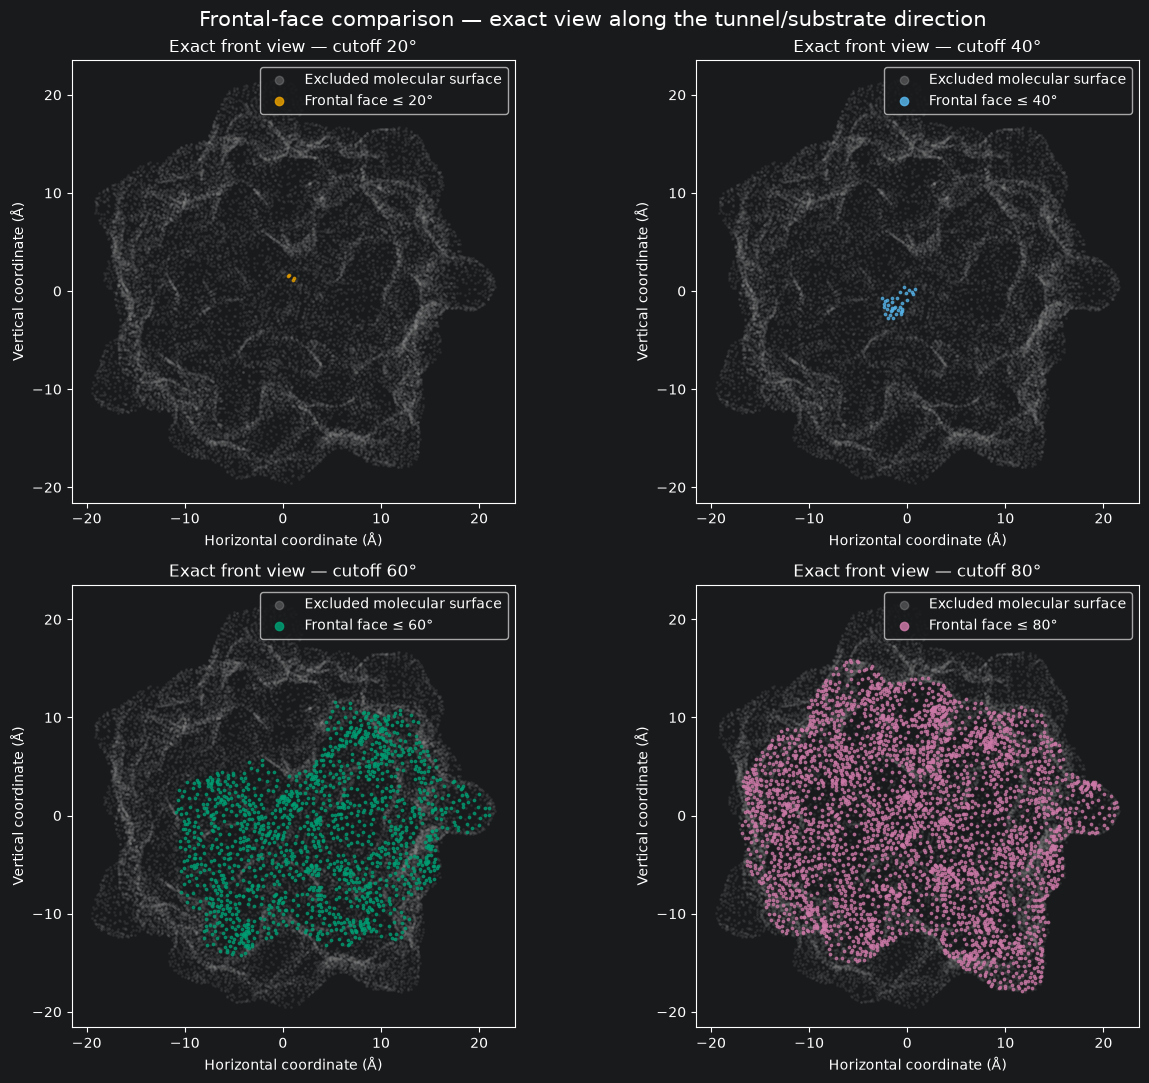

Saved figure: 02_angle_comparison_exact_side.png
Saved figure: 02_angle_comparison_exact_side.pdf


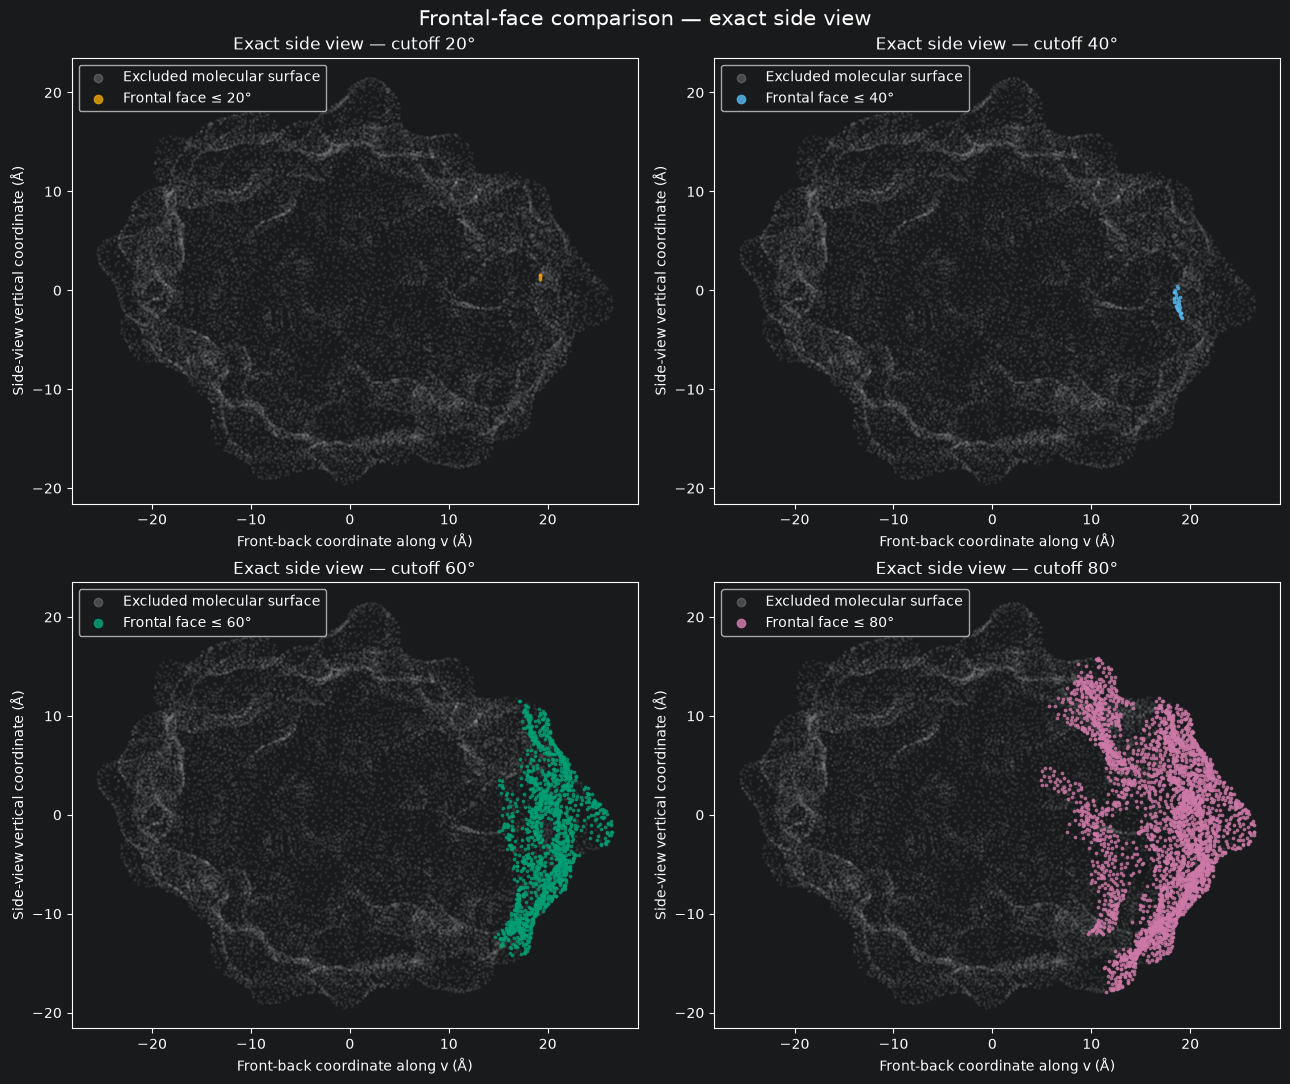

In [10]:

def draw_projected_mesh_panel(
    ax,
    mask,
    horizontal_axis,
    vertical_axis,
    color,
    title,
):
    """
    Draw triangle centroids in an exact orthographic coordinate system.
    The excluded molecular surface is shown faintly for context.
    """
    h = face_centroids @ horizontal_axis
    vv = face_centroids @ vertical_axis

    ax.scatter(
        h[~mask],
        vv[~mask],
        s=1.5,
        alpha=0.08,
        color="#9E9E9E",
        rasterized=True,
    )

    ax.scatter(
        h[mask],
        vv[mask],
        s=3.0,
        alpha=0.72,
        color=color,
        rasterized=True,
    )

    ax.set_aspect("equal", adjustable="box")
    ax.set_title(title)
    ax.set_xlabel("Horizontal coordinate (Å)")
    ax.set_ylabel("Vertical coordinate (Å)")


# -------------------------------------------------------------------------
# EXACT FRONT VIEW
# horizontal = u, vertical = w
# viewing direction = v
# -------------------------------------------------------------------------
fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 11),
)

for ax, angle_deg in zip(
    axes.flat,
    ANGLE_CUTOFFS_DEG,
):
    result = ANGLE_RESULTS[angle_deg]

    draw_projected_mesh_panel(
        ax=ax,
        mask=result["mask"],
        horizontal_axis=u,
        vertical_axis=w,
        color=ANGLE_COLORS[angle_deg],
        title=f"Exact front view — cutoff {angle_deg:.0f}°",
    )
    ax.scatter([], [], color="#9E9E9E", alpha=0.35, label="Excluded molecular surface")
    ax.scatter([], [], color=ANGLE_COLORS[angle_deg], alpha=0.85,
               label=f"Frontal face ≤ {angle_deg:.0f}°")
    ax.legend(loc="best")

fig.suptitle(
    "Frontal-face comparison — exact view along the tunnel/substrate direction",
    fontsize=15,
)
plt.tight_layout()
save_matplotlib_figure(
    fig,
    "01_angle_comparison_exact_front",
)
plt.show()


# -------------------------------------------------------------------------
# EXACT SIDE VIEW
#
# The front-back depth axis is v and the vertical direction is w.
# Looking along u gives a true side view.
# -------------------------------------------------------------------------
fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 11),
)

for ax, angle_deg in zip(
    axes.flat,
    ANGLE_CUTOFFS_DEG,
):
    result = ANGLE_RESULTS[angle_deg]

    depth_coord = face_centroids @ v
    vertical_coord = face_centroids @ w

    mask = result["mask"]

    ax.scatter(
        depth_coord[~mask],
        vertical_coord[~mask],
        s=1.5,
        alpha=0.08,
        color="#9E9E9E",
        rasterized=True,
    )

    ax.scatter(
        depth_coord[mask],
        vertical_coord[mask],
        s=3.0,
        alpha=0.72,
        color=ANGLE_COLORS[angle_deg],
        rasterized=True,
    )

    ax.set_aspect("equal", adjustable="box")
    ax.set_title(
        f"Exact side view — cutoff {angle_deg:.0f}°"
    )
    ax.set_xlabel(
        "Front-back coordinate along v (Å)"
    )
    ax.set_ylabel(
        "Side-view vertical coordinate (Å)"
    )
    ax.scatter([], [], color="#9E9E9E", alpha=0.35, label="Excluded molecular surface")
    ax.scatter([], [], color=ANGLE_COLORS[angle_deg], alpha=0.85,
               label=f"Frontal face ≤ {angle_deg:.0f}°")
    ax.legend(loc="best")

fig.suptitle(
    "Frontal-face comparison — exact side view",
    fontsize=15,
)
plt.tight_layout()
save_matplotlib_figure(
    fig,
    "02_angle_comparison_exact_side",
)
plt.show()



## Interactive 3D view — keep the protein freely rotatable

### Italiano

Questa è la vista che puoi muovere liberamente nello spazio.

Il menu permette di scegliere 20°, 40°, 60° o 80° senza ricostruire la figura. La proteina esclusa rimane semitrasparente; la regione selezionata usa lo stesso colore delle figure comparative.

Questa vista non sostituisce le viste frontale/laterale esatte: serve a capire meglio la topologia 3D, le cavità e il modo in cui la boundary gira attorno alla proteina.

### English

The protein remains freely rotatable. Use the dropdown to switch between the four angle hypotheses while preserving the same color coding used in the exact front/side comparisons.


In [11]:

def boundary_trace_for_edges(bedges, name, color):
    bx, by, bz = [], [], []

    for a, b in bedges:
        p0 = vertices[a]
        p1 = vertices[b]

        bx.extend([p0[0], p1[0], None])
        by.extend([p0[1], p1[1], None])
        bz.extend([p0[2], p1[2], None])

    return go.Scatter3d(
        x=bx,
        y=by,
        z=bz,
        mode="lines",
        name=name,
        line=dict(
            width=5,
            color=color,
        ),
    )


fig = go.Figure()

# Background molecular surface.
background = subset_mesh_trace(
    vertices,
    faces,
    np.ones(len(faces), dtype=bool),
    "Complete molecular surface",
    opacity=0.12,
)

if background is not None:
    fig.add_trace(background)

trace_groups = []

for angle_deg in ANGLE_CUTOFFS_DEG:
    result = ANGLE_RESULTS[angle_deg]
    color = ANGLE_COLORS[angle_deg]

    mesh = go.Mesh3d(
        x=vertices[:, 0],
        y=vertices[:, 1],
        z=vertices[:, 2],
        i=faces[result["mask"], 0],
        j=faces[result["mask"], 1],
        k=faces[result["mask"], 2],
        name=f"Frontal face ≤ {angle_deg:.0f}°",
        opacity=0.82,
        color=color,
        flatshading=True,
        visible=(angle_deg == FRONTAL_ANGLE_DEG),
    )

    boundary = boundary_trace_for_edges(
        result["boundary_edges"],
        f"Boundary {angle_deg:.0f}°",
        color,
    )
    boundary.visible = (
        angle_deg == FRONTAL_ANGLE_DEG
    )

    fig.add_trace(mesh)
    fig.add_trace(boundary)

    trace_groups.append(
        (angle_deg, len(fig.data) - 2, len(fig.data) - 1)
    )


# Tunnel / substrate direction.
axis_extent = (
    np.max(
        np.linalg.norm(
            vertices,
            axis=1,
        )
    )
    * 1.25
)

axis_start = -0.25 * axis_extent * v
axis_end = axis_extent * v

fig.add_trace(
    go.Scatter3d(
        x=[
            axis_start[0],
            axis_end[0],
        ],
        y=[
            axis_start[1],
            axis_end[1],
        ],
        z=[
            axis_start[2],
            axis_end[2],
        ],
        mode="lines",
        name="Tunnel / surface direction",
        line=dict(
            width=7,
            color="#7B2CBF",
        ),
    )
)

direction_trace_index = len(fig.data) - 1
background_trace_index = 0


buttons = []

for angle_deg, mesh_index, boundary_index in trace_groups:
    visibility_flags = [
        False
    ] * len(fig.data)

    visibility_flags[
        background_trace_index
    ] = True

    visibility_flags[
        mesh_index
    ] = True

    visibility_flags[
        boundary_index
    ] = True

    visibility_flags[
        direction_trace_index
    ] = True

    buttons.append(
        dict(
            label=f"{angle_deg:.0f}°",
            method="update",
            args=[
                {
                    "visible": visibility_flags
                },
                {
                    "title":
                    f"Interactive 3D frontal face — cutoff {angle_deg:.0f}°"
                },
            ],
        )
    )


fig.update_layout(
    title=(
        f"Interactive 3D frontal face — cutoff "
        f"{FRONTAL_ANGLE_DEG:.0f}°"
    ),
    scene=dict(
        aspectmode="data",
    ),
    updatemenus=[
        dict(
            type="dropdown",
            buttons=buttons,
            direction="down",
            x=0.02,
            y=1.08,
            xanchor="left",
            yanchor="top",
        )
    ],
    legend=dict(
        orientation="h"
    ),
)

save_plotly_figure(
    fig,
    f"03_interactive_3D_angle_default_{FRONTAL_ANGLE_DEG:.0f}deg",
)
fig.show()


Saved figure: 03_interactive_3D_angle_default_60deg.html
Saved figure: 03_interactive_3D_angle_default_60deg.png
Saved figure: 03_interactive_3D_angle_default_60deg.pdf



## Step 6 — Visual proof of the frontal-face boundary

### Spiegazione italiana

Questa è una prova visiva fondamentale.

La figura 3D deve permettere di controllare quattro elementi separatamente:

1. l'intera superficie molecolare;
2. la componente classificata come frontal face;
3. il bordo della frontal face;
4. la direzione comune del tunnel.

Il bordo non dovrebbe essere costretto ad assumere una forma circolare. Se la proteina è irregolare, anche il bordo deve essere irregolare.

Nella proiezione 2D frontale vediamo la stessa regione prima della trasformazione sferica SURFMAP. È utile perché permette di controllare immediatamente se il contorno segue la geometria reale e se compaiono regioni isolate inattese.

Se il risultato visivo non corrisponde alla faccia fisicamente rivolta verso il substrato, **non si deve proseguire con il core**: prima va controllata la coerenza della mesh e dell'allineamento.

### English explanation

This is a mandatory visual validation.

The 3D figure separately shows the complete molecular surface, the selected frontal component, its boundary, and the common tunnel direction.

The frontal boundary is not forced to be circular. An irregular protein should produce an irregular boundary.

The frontal 2D projection shows the same classification before SURFMAP spherical flattening.


### Angle interpretation

The displayed boundary corresponds to the current value of `FRONTAL_ANGLE_DEG`.  
Changing the angle changes the geometrical definition of the frontal face itself; changing `CORE_DEPTH_A` only changes the core inside that already-defined face.


Saved figure: 04_3D_validation_frontal_face_60deg.html
Saved figure: 04_3D_validation_frontal_face_60deg.png
Saved figure: 04_3D_validation_frontal_face_60deg.pdf


Saved figure: 05_2D_validation_frontal_face_60deg.png
Saved figure: 05_2D_validation_frontal_face_60deg.pdf


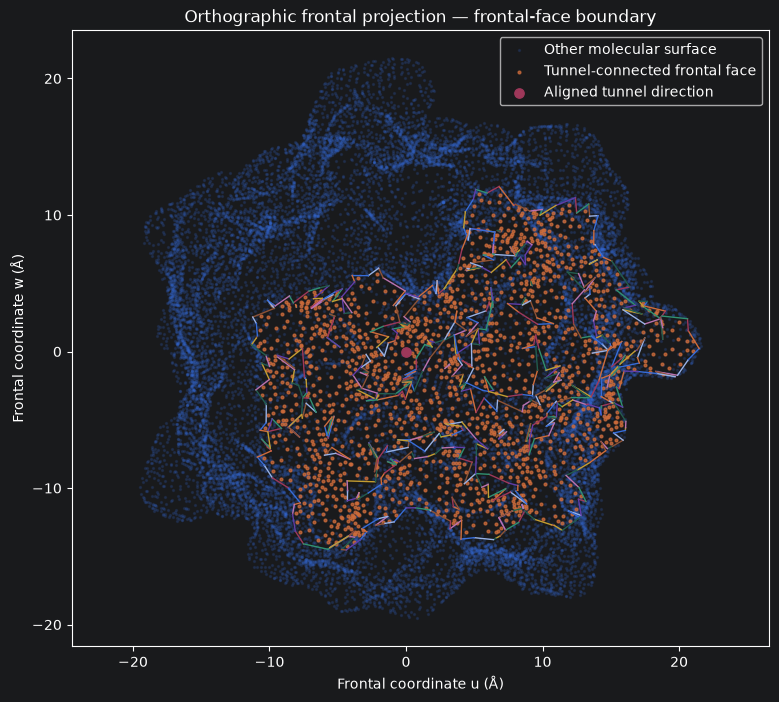

In [12]:

def subset_mesh_trace(vertices, faces, mask, name, opacity=0.55):
    selected = faces[mask]
    if len(selected) == 0:
        return None
    return go.Mesh3d(
        x=vertices[:, 0], y=vertices[:, 1], z=vertices[:, 2],
        i=selected[:, 0], j=selected[:, 1], k=selected[:, 2],
        name=name, opacity=opacity, flatshading=True
    )


fig = go.Figure()

other_trace = subset_mesh_trace(
    vertices, faces, ~frontal_mask, "Other molecular surface", opacity=0.18
)
front_trace = subset_mesh_trace(
    vertices, faces, frontal_mask, "Tunnel-connected frontal face", opacity=0.75
)

if other_trace is not None:
    fig.add_trace(other_trace)
if front_trace is not None:
    fig.add_trace(front_trace)

if len(boundary_edges):
    bx, by, bz = [], [], []
    for a, b in boundary_edges:
        p0, p1 = vertices[a], vertices[b]
        bx.extend([p0[0], p1[0], None])
        by.extend([p0[1], p1[1], None])
        bz.extend([p0[2], p1[2], None])
    fig.add_trace(go.Scatter3d(
        x=bx, y=by, z=bz, mode="lines",
        name="Frontal-face boundary",
        line=dict(width=5)
    ))

axis_extent = np.max(np.linalg.norm(vertices, axis=1)) * 1.25
axis_start = -0.25 * axis_extent * v
axis_end = axis_extent * v
fig.add_trace(go.Scatter3d(
    x=[axis_start[0], axis_end[0]],
    y=[axis_start[1], axis_end[1]],
    z=[axis_start[2], axis_end[2]],
    mode="lines",
    name="Tunnel / surface direction",
    line=dict(width=6)
))

fig.update_layout(
    title="3D validation — tunnel-connected frontal face and boundary",
    scene=dict(aspectmode="data"),
    legend=dict(orientation="h")
)
save_plotly_figure(
    fig,
    f"04_3D_validation_frontal_face_{FRONTAL_ANGLE_DEG:.0f}deg",
)
fig.show()


plt.figure(figsize=(9, 8))
plt.scatter(
    face_u[~frontal_mask], face_w[~frontal_mask],
    s=2, alpha=0.15, label="Other molecular surface"
)
plt.scatter(
    face_u[frontal_mask], face_w[frontal_mask],
    s=4, alpha=0.75, label="Tunnel-connected frontal face"
)

if len(boundary_edges):
    for a, b in boundary_edges:
        p = vertices[[a, b]]
        plt.plot(p @ u, p @ w, linewidth=1.0)

plt.scatter([0], [0], s=45, label="Aligned tunnel direction")
plt.xlabel("Frontal coordinate u (Å)")
plt.ylabel("Frontal coordinate w (Å)")
plt.title("Orthographic frontal projection — frontal-face boundary")
plt.axis("equal")
plt.legend()
save_matplotlib_figure(
    plt.gcf(),
    f"05_2D_validation_frontal_face_{FRONTAL_ANGLE_DEG:.0f}deg",
)
plt.show()



## Step 7 — Calculate the geometric core from the first-contact plane

### Spiegazione italiana

Adesso lavoriamo **solo all'interno della frontal face definita dal cutoff angolare corrente**.

Tra tutti i vertici appartenenti alla faccia frontale troviamo quello con la coordinata più avanzata lungo **v**:

\[
d_{contact}=\max(P\cdot v)
\]

Questo valore definisce il piano di primo contatto.

Per ogni triangolo della faccia frontale calcoliamo:

\[
h_i=d_{contact}-(C_i\cdot v)
\]

dove \(C_i\) è il centro del triangolo.

Il triangolo appartiene al core se:

\[
h_i\le CORE\_DEPTH\_A
\]

Questo significa che il core può essere molto irregolare e può arrivare vicino alla frontal-face boundary in alcune zone, mentre in altre può rimanere più centrale. Non imponiamo che debba avere una particolare forma.

La cosa importante è che:

\[
\text{Core}\subseteq\text{Frontal face}
\]

quindi il core non può attraversare il bordo geometrico e finire sulla faccia laterale.

### English explanation

The core is calculated **only inside the frontal face defined by the current angular cutoff**.

The most advanced frontal vertex defines:

\[
d_{contact}=\max(P\cdot v)
\]

For each frontal triangle:

\[
h_i=d_{contact}-(C_i\cdot v)
\]

The triangle is included in the geometric core when:

\[
h_i\le CORE\_DEPTH\_A
\]

The core is allowed to be irregular. In some parts it may approach the frontal-face boundary; in others it may remain more central.

By construction:

\[
\text{Core}\subseteq\text{Frontal face}
\]


In [13]:

front_vertex_ids = np.unique(faces[frontal_mask].ravel())
contact_depth = float(np.max(vertices[front_vertex_ids] @ v))

depth_from_contact = contact_depth - face_depth


def core_mask_for_depth(core_depth_a):
    return frontal_mask & (depth_from_contact <= float(core_depth_a))


core_mask = core_mask_for_depth(CORE_DEPTH_A)

summary = pd.DataFrame([{
    "protein": protein_name,
    "old_run_tunnel_x_A": float(TUNNEL_COORD_OLD_RUN[0]),
    "old_run_tunnel_y_A": float(TUNNEL_COORD_OLD_RUN[1]),
    "old_run_tunnel_z_A": float(TUNNEL_COORD_OLD_RUN[2]),
    "frontal_angle_deg": FRONTAL_ANGLE_DEG,
    "core_depth_A": CORE_DEPTH_A,
    "contact_plane_axis_coordinate_A": contact_depth,
    "frontal_face_area_A2": float(face_areas[frontal_mask].sum()),
    "core_area_A2": float(face_areas[core_mask].sum()),
    "core_fraction_of_frontal_face_pct": (
        float(face_areas[core_mask].sum() / face_areas[frontal_mask].sum() * 100.0)
        if frontal_mask.any() else np.nan
    ),
    "frontal_boundary_edges": int(len(boundary_edges)),
}])

display(summary)


,protein,old_run_tunnel_x_A,old_run_tunnel_y_A,old_run_tunnel_z_A,frontal_angle_deg,core_depth_A,contact_plane_axis_coordinate_A,frontal_face_area_A2,core_area_A2,core_fraction_of_frontal_face_pct,frontal_boundary_edges
0,1CEX_cutfv_4rev,13.636571,50.498968,14.826886,60.0,5.0,26.623307,611.495328,123.702672,20.229537,598



# Geometric-core comparison — 4 Å, 5 Å and 6 Å

## Italiano

La **frontal face usata per il core è quella del cutoff angolare di default `FRONTAL_ANGLE_DEG`**.

Questa sezione non modifica la frontal-face boundary. Confronta soltanto tre diverse profondità dietro il first-contact plane:

\[
4\ \AA,\quad 5\ \AA,\quad 6\ \AA
\]

Per ciascuna vengono mostrate:

- vista frontale esatta;
- vista laterale esatta;
- area 3D del core;
- percentuale della frontal face inclusa.

Quindi puoi valutare contemporaneamente quanto cambia il core spostando la profondità di un solo Å.

La selezione a 4 Å è la più stretta, quella a 6 Å la più inclusiva.

Il cutoff del core rimane un criterio geometrico iniziale e **non significa** che interazioni oltre quella profondità siano nulle.

## English

The core comparison uses the frontal face defined by the current default `FRONTAL_ANGLE_DEG`.

The frontal-face boundary itself is kept fixed while three depths behind the first-contact plane are compared:

\[
4\ \AA,\quad5\ \AA,\quad6\ \AA
\]

Exact front and side views, 3D core area and frontal-face coverage are shown for every depth.


,core_depth_A,core_area_A2,frontal_face_area_A2,core_fraction_of_frontal_face_pct
0,4.0,53.006486,611.495328,8.668339
1,5.0,123.702672,611.495328,20.229537
2,6.0,234.000915,611.495328,38.267000


Saved figure: 06_core_comparison_exact_front.png
Saved figure: 06_core_comparison_exact_front.pdf


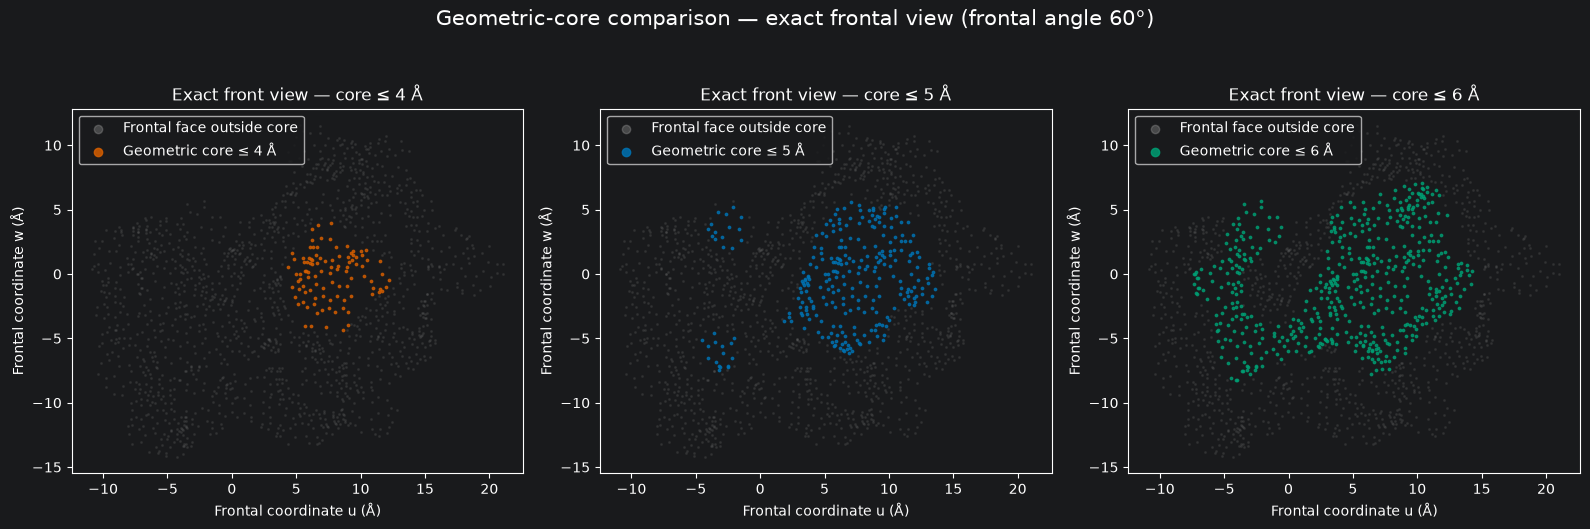

Saved figure: 07_core_comparison_exact_side.png
Saved figure: 07_core_comparison_exact_side.pdf


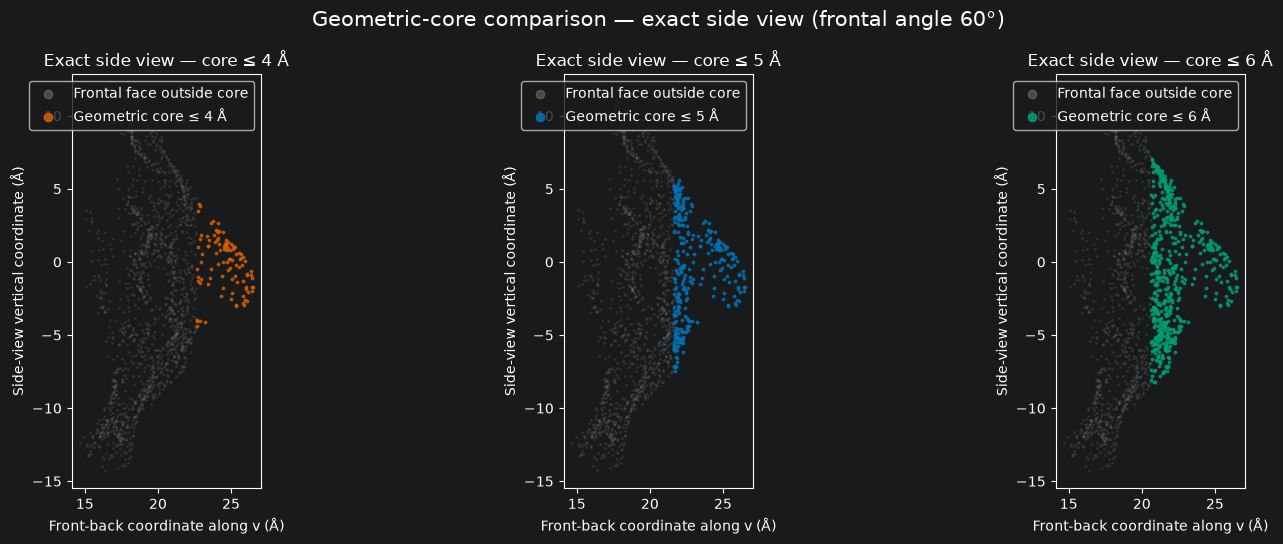

In [14]:

CORE_RESULTS = {}

for core_depth_a in CORE_DEPTHS_A:
    cmask = core_mask_for_depth(
        core_depth_a
    )

    CORE_RESULTS[float(core_depth_a)] = {
        "mask": cmask,
        "area_A2": float(
            face_areas[cmask].sum()
        ),
    }


core_comparison_table = pd.DataFrame([
    {
        "core_depth_A": depth,
        "core_area_A2":
            CORE_RESULTS[depth]["area_A2"],
        "frontal_face_area_A2":
            float(
                face_areas[
                    frontal_mask
                ].sum()
            ),
        "core_fraction_of_frontal_face_pct":
            (
                CORE_RESULTS[depth]["area_A2"]
                /
                float(
                    face_areas[
                        frontal_mask
                    ].sum()
                )
                * 100.0
                if frontal_mask.any()
                else np.nan
            ),
    }
    for depth in CORE_DEPTHS_A
])

core_comparison_table.to_csv(
    PROTEIN_OUTPUT_DIR / "05_core_comparison.csv",
    index=False,
)

display(core_comparison_table)


# -------------------------------------------------------------------------
# EXACT FRONT VIEW — 4, 5, 6 Å
# -------------------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5.5),
)

for ax, depth in zip(
    axes,
    CORE_DEPTHS_A,
):
    cmask = CORE_RESULTS[depth]["mask"]

    ax.scatter(
        face_u[
            frontal_mask & ~cmask
        ],
        face_w[
            frontal_mask & ~cmask
        ],
        s=1.5,
        alpha=0.10,
        color="#9E9E9E",
        rasterized=True,
    )

    ax.scatter(
        face_u[cmask],
        face_w[cmask],
        s=3.0,
        alpha=0.78,
        color=CORE_COLORS[depth],
        rasterized=True,
    )

    ax.set_aspect(
        "equal",
        adjustable="box",
    )

    ax.set_title(
        f"Exact front view — core ≤ {depth:.0f} Å"
    )

    ax.set_xlabel(
        "Frontal coordinate u (Å)"
    )

    ax.set_ylabel(
        "Frontal coordinate w (Å)"
    )
    ax.scatter([], [], color="#9E9E9E", alpha=0.35,
               label="Frontal face outside core")
    ax.scatter([], [], color=CORE_COLORS[depth], alpha=0.85,
               label=f"Geometric core ≤ {depth:.0f} Å")
    ax.legend(loc="best")


fig.suptitle(
    (
        "Geometric-core comparison — exact frontal view "
        f"(frontal angle {FRONTAL_ANGLE_DEG:.0f}°)"
    ),
    fontsize=15,
)
plt.tight_layout()
save_matplotlib_figure(
    fig,
    "06_core_comparison_exact_front",
)
plt.show()


# -------------------------------------------------------------------------
# EXACT SIDE VIEW — 4, 5, 6 Å
# -------------------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5.5),
)

depth_axis = face_centroids @ v
side_vertical = face_centroids @ w

for ax, depth in zip(
    axes,
    CORE_DEPTHS_A,
):
    cmask = CORE_RESULTS[depth]["mask"]

    ax.scatter(
        depth_axis[
            frontal_mask & ~cmask
        ],
        side_vertical[
            frontal_mask & ~cmask
        ],
        s=1.5,
        alpha=0.10,
        color="#9E9E9E",
        rasterized=True,
    )

    ax.scatter(
        depth_axis[cmask],
        side_vertical[cmask],
        s=3.0,
        alpha=0.78,
        color=CORE_COLORS[depth],
        rasterized=True,
    )

    ax.set_aspect(
        "equal",
        adjustable="box",
    )

    ax.set_title(
        f"Exact side view — core ≤ {depth:.0f} Å"
    )

    ax.set_xlabel(
        "Front-back coordinate along v (Å)"
    )

    ax.set_ylabel(
        "Side-view vertical coordinate (Å)"
    )
    ax.scatter([], [], color="#9E9E9E", alpha=0.35,
               label="Frontal face outside core")
    ax.scatter([], [], color=CORE_COLORS[depth], alpha=0.85,
               label=f"Geometric core ≤ {depth:.0f} Å")
    ax.legend(loc="best")


fig.suptitle(
    (
        "Geometric-core comparison — exact side view "
        f"(frontal angle {FRONTAL_ANGLE_DEG:.0f}°)"
    ),
    fontsize=15,
)
plt.tight_layout()
save_matplotlib_figure(
    fig,
    "07_core_comparison_exact_side",
)
plt.show()



## Interactive 3D core comparison

Questa vista mantiene la rotazione libera anche per il core.

Il menu permette di passare tra **4 Å, 5 Å e 6 Å** mantenendo la stessa frontal face. La frontal-face boundary rimane visibile come riferimento esterno.


In [15]:

fig = go.Figure()

# Other molecular surface.
tr = subset_mesh_trace(
    vertices,
    faces,
    ~frontal_mask,
    "Outside frontal face",
    opacity=0.08,
)

if tr is not None:
    fig.add_trace(tr)

outside_front_index = len(fig.data) - 1

# Frontal face background.
tr = subset_mesh_trace(
    vertices,
    faces,
    frontal_mask,
    "Complete frontal face",
    opacity=0.15,
)

if tr is not None:
    fig.add_trace(tr)

front_background_index = len(fig.data) - 1


core_groups = []

for depth in CORE_DEPTHS_A:
    cmask = CORE_RESULTS[depth]["mask"]

    core_trace = go.Mesh3d(
        x=vertices[:, 0],
        y=vertices[:, 1],
        z=vertices[:, 2],
        i=faces[cmask, 0],
        j=faces[cmask, 1],
        k=faces[cmask, 2],
        name=f"Core ≤ {depth:.0f} Å",
        opacity=0.86,
        color=CORE_COLORS[depth],
        flatshading=True,
        visible=(depth == CORE_DEPTH_A),
    )

    fig.add_trace(core_trace)
    core_groups.append(
        (depth, len(fig.data) - 1)
    )


# Fixed frontal-face boundary.
if len(boundary_edges):
    boundary_trace = boundary_trace_for_edges(
        boundary_edges,
        "Frontal-face boundary",
        "#00C2A8",
    )

    fig.add_trace(boundary_trace)
    boundary_index = len(fig.data) - 1
else:
    boundary_index = None


# Tunnel direction.
axis_extent = (
    np.max(
        np.linalg.norm(
            vertices,
            axis=1,
        )
    )
    * 1.25
)

axis_start = -0.25 * axis_extent * v
axis_end = axis_extent * v

fig.add_trace(
    go.Scatter3d(
        x=[
            axis_start[0],
            axis_end[0],
        ],
        y=[
            axis_start[1],
            axis_end[1],
        ],
        z=[
            axis_start[2],
            axis_end[2],
        ],
        mode="lines",
        name="Tunnel / surface direction",
        line=dict(
            width=7,
            color="#7B2CBF",
        ),
    )
)

direction_index = len(fig.data) - 1


buttons = []

for depth, core_index in core_groups:
    flags = [
        False
    ] * len(fig.data)

    flags[
        outside_front_index
    ] = True

    flags[
        front_background_index
    ] = True

    flags[
        core_index
    ] = True

    if boundary_index is not None:
        flags[
            boundary_index
        ] = True

    flags[
        direction_index
    ] = True

    buttons.append(
        dict(
            label=f"{depth:.0f} Å",
            method="update",
            args=[
                {
                    "visible": flags
                },
                {
                    "title":
                    f"Interactive geometric core — depth ≤ {depth:.0f} Å"
                },
            ],
        )
    )


fig.update_layout(
    title=(
        f"Interactive geometric core — depth ≤ "
        f"{CORE_DEPTH_A:.0f} Å"
    ),
    scene=dict(
        aspectmode="data",
    ),
    updatemenus=[
        dict(
            type="dropdown",
            buttons=buttons,
            x=0.02,
            y=1.08,
            xanchor="left",
            yanchor="top",
        )
    ],
    legend=dict(
        orientation="h",
    ),
)

save_plotly_figure(
    fig,
    f"08_interactive_3D_core_default_{CORE_DEPTH_A:.0f}A",
)
fig.show()


Saved figure: 08_interactive_3D_core_default_5A.html
Saved figure: 08_interactive_3D_core_default_5A.png
Saved figure: 08_interactive_3D_core_default_5A.pdf



## Optional continuous angle slider

### Spiegazione italiana

Questa sezione opzionale permette di esplorare anche valori intermedi dopo aver confrontato i quattro cutoff principali **20°, 40°, 60° e 80°** senza dover modificare ogni volta il notebook e rieseguire tutto manualmente.

La visibilità rimane identica. Per ogni valore dell'angolo viene ricalcolato soltanto:

\[
\cos(\theta_{\max})
\]

e quindi il criterio:

\[
n\cdot v\ge\cos(\theta_{\max})
\]

Poi viene nuovamente estratta la componente connessa alla direzione centrale del tunnel.

La figura mostra:

- superficie che rimane dentro la frontal face;
- superficie esclusa;
- nuova boundary;
- area totale della frontal face.

Questo permette di capire concretamente quanto cambia la faccia quando passi, per esempio, da 70° a 60°.

### English explanation

This section interactively compares angle cutoffs such as **60°, 70°, 80° and 90°**.

Visibility remains unchanged. For each selected angle, the notebook recalculates:

\[
n\cdot v\ge\cos(\theta_{\max})
\]

and then recomputes the tunnel-connected frontal component.

The plots show the retained surface, excluded surface, resulting boundary and total frontal-face area.


In [16]:

def frontal_component_for_angle(angle_deg):
    angle_deg = float(angle_deg)
    cos_cut = float(np.cos(np.deg2rad(angle_deg)))

    angle_candidate = is_visible & (normal_dot_view >= cos_cut)

    angle_seed, _, _ = central_seed_face(visibility, angle_candidate)

    mask = np.zeros(len(faces), dtype=bool)
    q = deque([angle_seed])
    mask[angle_seed] = True

    while q:
        current = q.popleft()
        for nb in adjacency[current]:
            if angle_candidate[nb] and not mask[nb]:
                mask[nb] = True
                q.append(nb)

    angle_boundary = []
    for edge, attached in edge_to_faces.items():
        inside = [fi for fi in attached if mask[fi]]
        outside = [fi for fi in attached if not mask[fi]]
        if inside and (outside or len(attached) == 1):
            angle_boundary.append(edge)

    return mask, np.asarray(angle_boundary, dtype=np.int64), cos_cut


def show_angle_cutoff(angle_deg):
    angle_deg = float(angle_deg)
    mask, bedges, cos_cut = frontal_component_for_angle(angle_deg)

    fig = go.Figure()

    tr = subset_mesh_trace(
        vertices, faces, ~mask,
        "Excluded molecular surface", opacity=0.12
    )
    if tr is not None:
        fig.add_trace(tr)

    tr = subset_mesh_trace(
        vertices, faces, mask,
        f"Frontal face ≤ {angle_deg:.1f}°", opacity=0.78
    )
    if tr is not None:
        fig.add_trace(tr)

    if len(bedges):
        bx, by, bz = [], [], []
        for a, b in bedges:
            p0, p1 = vertices[a], vertices[b]
            bx.extend([p0[0], p1[0], None])
            by.extend([p0[1], p1[1], None])
            bz.extend([p0[2], p1[2], None])
        fig.add_trace(go.Scatter3d(
            x=bx, y=by, z=bz,
            mode="lines",
            name="Angle-controlled frontal-face boundary",
            line=dict(width=5)
        ))

    fig.update_layout(
        title=f"3D frontal-face comparison — maximum normal angle {angle_deg:.1f}°",
        scene=dict(aspectmode="data"),
        legend=dict(orientation="h")
    )
    save_plotly_figure(
        fig,
        f"09_angle_slider_3D_{angle_deg:.1f}deg",
    )
    fig.show()

    plt.figure(figsize=(9, 8))
    plt.scatter(
        face_u[~mask], face_w[~mask],
        s=2, alpha=0.12, label="Excluded molecular surface"
    )
    plt.scatter(
        face_u[mask], face_w[mask],
        s=4, alpha=0.75, label=f"Frontal face ≤ {angle_deg:.1f}°"
    )

    if len(bedges):
        for a, b in bedges:
            p = vertices[[a, b]]
            plt.plot(p @ u, p @ w, linewidth=1.0)

    plt.scatter([0], [0], s=45, label="Aligned tunnel direction")
    plt.xlabel("Frontal coordinate u (Å)")
    plt.ylabel("Frontal coordinate w (Å)")
    plt.title(f"Orthographic frontal projection — maximum normal angle {angle_deg:.1f}°")
    plt.axis("equal")
    plt.legend()
    save_matplotlib_figure(
        plt.gcf(),
        f"10_angle_slider_2D_{angle_deg:.1f}deg",
    )
    plt.show()

    area = float(face_areas[mask].sum())
    display(pd.DataFrame([{
        "frontal_angle_deg": angle_deg,
        "cosine_cutoff": cos_cut,
        "frontal_face_area_A2": area,
        "frontal_face_triangles": int(mask.sum()),
        "boundary_edges": int(len(bedges)),
    }]))


angle_widget = widgets.FloatSlider(
    value=FRONTAL_ANGLE_DEG,
    min=20.0,
    max=90.0,
    step=1.0,
    description="Angle (°):",
    continuous_update=False
)

angle_output = widgets.interactive_output(
    show_angle_cutoff,
    {"angle_deg": angle_widget}
)

display(angle_widget, angle_output)


FloatSlider(value=60.0, continuous_update=False, description='Angle (°):', max=90.0, min=20.0, step=1.0)

Output()


## Step 8 — Interactive visual test of 4 Å, 5 Å, 6 Å or any other core depth

### Spiegazione italiana

Qui la frontal-face boundary **non viene ricalcolata e non cambia**.

Varia soltanto la profondità del core.

Questo è utile perché puoi scrivere direttamente:

- `4.0`
- `5.0`
- `6.0`

e vedere quanto cambia la regione candidata.

Per ogni valore il notebook mostra:

- il core in 3D;
- la frontal face che rimane fuori dal core;
- la frontal-face boundary, che resta il limite esterno invalicabile;
- la proiezione frontale;
- area del core e percentuale della frontal face occupata.

Questa visualizzazione serve a scegliere successivamente una profondità iniziale ragionevole **prima** di introdurre l'estensione chimica.

### English explanation

The frontal-face boundary is fixed. Only the core depth changes.

Enter any value such as 4, 5 or 6 Å and inspect how much of the tunnel-connected frontal face is retained.

The interactive view reports the 3D core, the remaining frontal face, the fixed outer boundary, the frontal projection, and the corresponding areas.


In [17]:

def show_core(core_depth_a):
    core_depth_a = float(core_depth_a)
    cmask = core_mask_for_depth(core_depth_a)
    front_outside_core = frontal_mask & ~cmask

    fig = go.Figure()

    tr = subset_mesh_trace(
        vertices, faces, ~frontal_mask,
        "Outside frontal face", opacity=0.10
    )
    if tr is not None:
        fig.add_trace(tr)

    tr = subset_mesh_trace(
        vertices, faces, front_outside_core,
        "Frontal face outside core", opacity=0.30
    )
    if tr is not None:
        fig.add_trace(tr)

    tr = subset_mesh_trace(
        vertices, faces, cmask,
        f"Geometric core ≤ {core_depth_a:.1f} Å", opacity=0.85
    )
    if tr is not None:
        fig.add_trace(tr)

    if len(boundary_edges):
        bx, by, bz = [], [], []
        for a, b in boundary_edges:
            p0, p1 = vertices[a], vertices[b]
            bx.extend([p0[0], p1[0], None])
            by.extend([p0[1], p1[1], None])
            bz.extend([p0[2], p1[2], None])
        fig.add_trace(go.Scatter3d(
            x=bx, y=by, z=bz,
            mode="lines", name="Fixed frontal-face boundary",
            line=dict(width=5)
        ))

    fig.update_layout(
        title=f"3D geometric core — depth ≤ {core_depth_a:.1f} Å",
        scene=dict(aspectmode="data"),
        legend=dict(orientation="h")
    )
    save_plotly_figure(
        fig,
        f"11_core_slider_3D_{core_depth_a:.1f}A",
    )
    fig.show()

    plt.figure(figsize=(9, 8))
    plt.scatter(
        face_u[front_outside_core], face_w[front_outside_core],
        s=4, alpha=0.25, label="Frontal face outside core"
    )
    plt.scatter(
        face_u[cmask], face_w[cmask],
        s=5, alpha=0.80, label=f"Geometric core ≤ {core_depth_a:.1f} Å"
    )

    if len(boundary_edges):
        for a, b in boundary_edges:
            p = vertices[[a, b]]
            plt.plot(p @ u, p @ w, linewidth=1.0)

    plt.scatter([0], [0], s=45, label="Aligned tunnel direction")
    plt.xlabel("Frontal coordinate u (Å)")
    plt.ylabel("Frontal coordinate w (Å)")
    plt.title(f"Frontal projection — geometric core depth ≤ {core_depth_a:.1f} Å")
    plt.axis("equal")
    plt.legend()
    save_matplotlib_figure(
        plt.gcf(),
        f"12_core_slider_2D_{core_depth_a:.1f}A",
    )
    plt.show()

    core_area = float(face_areas[cmask].sum())
    front_area = float(face_areas[frontal_mask].sum())

    display(pd.DataFrame([{
        "core_depth_A": core_depth_a,
        "core_area_A2": core_area,
        "frontal_face_area_A2": front_area,
        "core_fraction_of_frontal_face_pct": (
            core_area / front_area * 100.0 if front_area else np.nan
        )
    }]))


core_depth_widget = widgets.FloatText(
    value=CORE_DEPTH_A,
    description="Core depth (Å):"
)

core_output = widgets.interactive_output(
    show_core,
    {"core_depth_a": core_depth_widget}
)

display(core_depth_widget, core_output)


FloatText(value=5.0, description='Core depth (Å):')

Output()


## Step 9 — Optional transfer of the 3D boundary/core to the SURFMAP 2D coordinates

### Spiegazione italiana

La ROI viene definita in 3D, ma la pipeline finale lavora sulla mappa SURFMAP 2D.

Se sono disponibili `*_shell.pdb` e `*_coord_list.txt`, questa sezione trasferisce l'informazione geometrica alla mappa.

Il principio è:

1. ogni punto della shell mantiene le sue coordinate 3D;
2. il punto viene associato alla regione della mesh 3D più vicina;
3. eredita:
   - appartenenza alla frontal face;
   - profondità dal first-contact plane;
   - appartenenza al core;
4. `index_sol` collega il punto della shell alla posizione `absc, ord` della mappa SURFMAP.

Quindi **non decidiamo il core sulla mappa deformata**. Decidiamo il core sulla proteina reale e poi chiediamo soltanto dove quella regione è finita sulla mappa.

### English explanation

The ROI is defined in 3D, whereas the final pipeline uses a SURFMAP 2D representation.

When the shell PDB and `coord_list` are available, each shell point inherits the nearest 3D mesh classification and is then transferred to its SURFMAP coordinates through `index_sol`.

Thus, the core is **not defined on the distorted map**. It is defined on the real protein surface and only then displayed on the map.


coord_list → shell mapping mode: serial
coord_list → shell match: 100.0 %
Mean shell → mesh distance: 0.33 Å
Saved figure: 13_SURFMAP_2D_frontal_face_and_core.png
Saved figure: 13_SURFMAP_2D_frontal_face_and_core.pdf


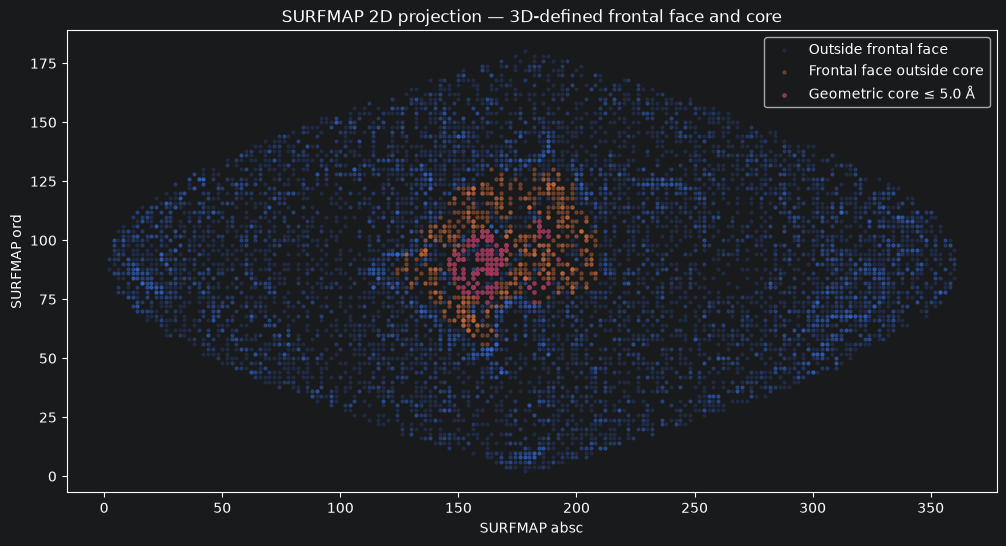

In [18]:

def read_shell_pdb(path):
    rows = []
    order = 0
    with open(path, "r", encoding="utf-8", errors="replace") as handle:
        for line in handle:
            if not line.startswith(("ATOM", "HETATM")):
                continue
            try:
                rows.append({
                    "serial": int(line[6:11]),
                    "order0": order,
                    "order1": order + 1,
                    "x": float(line[30:38]),
                    "y": float(line[38:46]),
                    "z": float(line[46:54]),
                })
                order += 1
            except ValueError:
                continue
    return pd.DataFrame(rows)


def read_coord_list(path):
    df = pd.read_csv(path, sep="\t")
    required = {"absc", "ord", "index_sol"}
    missing = required.difference(df.columns)
    if missing:
        raise ValueError(f"Missing coord_list columns: {sorted(missing)}")
    df["index_sol"] = pd.to_numeric(df["index_sol"], errors="coerce")
    df = df.dropna(subset=["index_sol"]).copy()
    df["index_sol"] = df["index_sol"].astype(int)
    return df


def best_index_mapping(coord, shell):
    modes = [
        ("serial", "serial"),
        ("zero_based", "order0"),
        ("one_based", "order1"),
    ]
    tests = []
    for name, col in modes:
        available = set(shell[col].astype(int).tolist())
        pct = float(coord["index_sol"].isin(available).mean() * 100.0)
        tests.append((pct, name, col))
    return max(tests)


if shell_path is None or coord_path is None:
    print("SURFMAP 2D transfer skipped: shell PDB and/or coord_list were not found.")
else:
    shell = read_shell_pdb(shell_path)
    coord = read_coord_list(coord_path)

    match_pct, mapping_mode, shell_index_col = best_index_mapping(coord, shell)

    shell_xyz = shell[["x", "y", "z"]].to_numpy(float)

    tree = cKDTree(face_centroids)
    nearest_distance, nearest_face = tree.query(shell_xyz, k=1)

    shell["nearest_face"] = nearest_face
    shell["mesh_mapping_distance_A"] = nearest_distance
    shell["is_frontal_face"] = frontal_mask[nearest_face]
    shell["depth_from_first_contact_A"] = contact_depth - (shell_xyz @ v)
    shell["is_core"] = (
        shell["is_frontal_face"].to_numpy(bool)
        & (shell["depth_from_first_contact_A"].to_numpy(float) <= CORE_DEPTH_A)
    )

    merged = coord.merge(
        shell[[shell_index_col, "x", "y", "z",
               "mesh_mapping_distance_A", "is_frontal_face",
               "depth_from_first_contact_A", "is_core"]],
        left_on="index_sol",
        right_on=shell_index_col,
        how="left",
    )

    print("coord_list → shell mapping mode:", mapping_mode)
    print("coord_list → shell match:", round(match_pct, 2), "%")
    print("Mean shell → mesh distance:",
          round(float(shell["mesh_mapping_distance_A"].mean()), 3), "Å")

    plt.figure(figsize=(12, 6))
    other = merged["is_frontal_face"] == False
    front = merged["is_frontal_face"] == True
    core = merged["is_core"] == True

    plt.scatter(
        merged.loc[other, "absc"], merged.loc[other, "ord"],
        s=4, alpha=0.15, label="Outside frontal face"
    )
    plt.scatter(
        merged.loc[front & ~core, "absc"], merged.loc[front & ~core, "ord"],
        s=5, alpha=0.35, label="Frontal face outside core"
    )
    plt.scatter(
        merged.loc[core, "absc"], merged.loc[core, "ord"],
        s=6, alpha=0.85, label=f"Geometric core ≤ {CORE_DEPTH_A:.1f} Å"
    )

    plt.xlabel("SURFMAP absc")
    plt.ylabel("SURFMAP ord")
    plt.title("SURFMAP 2D projection — 3D-defined frontal face and core")
    plt.legend()
    save_matplotlib_figure(
        plt.gcf(),
        "13_SURFMAP_2D_frontal_face_and_core",
    )
    plt.show()

    merged.to_csv(
        PROTEIN_OUTPUT_DIR / "06_SURFMAP_2D_frontal_face_and_core.csv",
        index=False
    )



## Step 10 — Export the geometrical evidence

### Spiegazione italiana

Gli output vengono salvati in modo che ogni decisione possa essere ricostruita.

Il file principale contiene un record per ogni triangolo della mesh con:

- coordinate del centro del triangolo;
- area;
- \(n\cdot v\);
- frazione visibile;
- classificazione front-facing;
- appartenenza alla frontal face connessa;
- profondità dal first-contact plane;
- appartenenza al core.

Il file del bordo contiene invece le coordinate 3D di ogni segmento che delimita la frontal face.

In questo modo il risultato non è soltanto una figura: rimangono i dati numerici usati per costruirla.

### English explanation

The exported tables make every geometrical decision traceable.

The face table stores triangle coordinates, area, \(n\cdot v\), visibility, tunnel-connected frontal-face membership, distance from the first-contact plane and geometric-core membership.

A separate boundary table stores the 3D coordinates of every frontal-face boundary segment.


In [19]:

core_mask = core_mask_for_depth(CORE_DEPTH_A)

face_table = pd.DataFrame({
    "old_run_tunnel_x_A": np.full(len(faces), TUNNEL_COORD_OLD_RUN[0]),
    "old_run_tunnel_y_A": np.full(len(faces), TUNNEL_COORD_OLD_RUN[1]),
    "old_run_tunnel_z_A": np.full(len(faces), TUNNEL_COORD_OLD_RUN[2]),
    "face_index": np.arange(len(faces), dtype=int),
    "centroid_x_A": face_centroids[:, 0],
    "centroid_y_A": face_centroids[:, 1],
    "centroid_z_A": face_centroids[:, 2],
    "surface_area_A2": face_areas,
    "normal_dot_view": normal_dot_view,
    "normal_angle_deg": normal_angle_deg,
    "frontal_angle_cutoff_deg": FRONTAL_ANGLE_DEG,
    "visible_fraction": visibility["visible_fraction"],
    "is_visible": is_visible,
    "is_front_facing": is_front_facing,
    "is_tunnel_connected_frontal_face": frontal_mask,
    "axis_depth_A": face_depth,
    "depth_from_first_contact_A": depth_from_contact,
    "is_geometric_core": core_mask,
})

face_table.to_csv(
    PROTEIN_OUTPUT_DIR / "01_face_classification.csv",
    index=False
)

boundary_rows = []
for edge_index, (a, b) in enumerate(boundary_edges):
    p0, p1 = vertices[a], vertices[b]
    boundary_rows.append({
        "boundary_segment": edge_index,
        "x1_A": p0[0], "y1_A": p0[1], "z1_A": p0[2],
        "x2_A": p1[0], "y2_A": p1[1], "z2_A": p1[2],
    })

boundary_table = pd.DataFrame(boundary_rows)
boundary_table.to_csv(
    PROTEIN_OUTPUT_DIR / "02_frontal_face_boundary_segments.csv",
    index=False
)

summary.to_csv(
    PROTEIN_OUTPUT_DIR / "03_core_summary.csv",
    index=False
)

print("Saved:")
print("-", PROTEIN_OUTPUT_DIR / "01_face_classification.csv")
print("-", PROTEIN_OUTPUT_DIR / "02_frontal_face_boundary_segments.csv")
print("-", PROTEIN_OUTPUT_DIR / "03_core_summary.csv")
if shell_path is not None and coord_path is not None:
    print("-", PROTEIN_OUTPUT_DIR / "06_SURFMAP_2D_frontal_face_and_core.csv")


Saved:
- /home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/SURFMAP_VALIDATION/SURFMAP_ROI/1CEX_cutfv_4rev_rad0.5_s2/01_face_classification.csv
- /home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/SURFMAP_VALIDATION/SURFMAP_ROI/1CEX_cutfv_4rev_rad0.5_s2/02_frontal_face_boundary_segments.csv
- /home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/SURFMAP_VALIDATION/SURFMAP_ROI/1CEX_cutfv_4rev_rad0.5_s2/03_core_summary.csv
- /home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/SURFMAP_VALIDATION/SURFMAP_ROI/1CEX_cutfv_4rev_rad0.5_s2/06_SURFMAP_2D_frontal_face_and_core.csv



# How to interpret the outputs

## Italiano

### 1. `normal_dot_view`

È il prodotto scalare:

\[
n\cdot v
\]

Non è un punteggio di qualità e non viene confrontato con una soglia scelta.

- positivo = il triangolo guarda ancora verso la superficie;
- negativo = il triangolo guarda dalla parte opposta;
- il passaggio di segno identifica la transizione geometrica equivalente allo spigolo di un oggetto con facce nette.

### 1A. `normal_angle_deg`

È l'angolo reale, in gradi, tra la normale del triangolo e la direzione frontale. Un triangolo può entrare nella frontal face solo se questo valore è minore o uguale a `FRONTAL_ANGLE_DEG`.

- 0° = superficie perfettamente rivolta verso il substrato;
- 60° = superficie inclinata di 60°;
- 90° = superficie tangente/laterale.

Changing the cutoff changes the geometrical definition of the frontal face itself.

### 2. `visible_fraction`

Indica quanto della proiezione del triangolo è effettivamente la prima superficie incontrata guardando lungo l'asse del tunnel.

- 0 = completamente nascosto;
- vicino a 1 = completamente visibile;
- intermedio = parzialmente occluso.

### 3. `is_tunnel_connected_frontal_face`

È la regione che soddisfa contemporaneamente:

- visibilità;
- \(n\cdot v>0\);
- connessione alla zona centrale dell'asse del tunnel.

Questa è la **frontal face** che useremo come limite esterno della futura ROI.

### 4. `frontal_face_boundary`

È il bordo geometrico esterno della faccia appena definita.

Non deve essere circolare.

È il limite oltre il quale la futura estensione della ROI non dovrebbe propagarsi se vogliamo mantenere una ROI appartenente alla stessa faccia geometrica.

### 5. `depth_from_first_contact_A`

È una distanza reale in Å lungo la direzione perpendicolare al piano di contatto:

\[
h_i=d_{contact}-d_i
\]

Non è una distanza 2D sulla mappa.

### 6. `is_geometric_core`

Indica la parte della frontal face che si trova entro `CORE_DEPTH_A` dal first-contact plane.

Prova inizialmente 4, 5 e 6 Å e guarda visivamente quanto cambia.

Non scegliere il valore soltanto perché produce una forma “bella”: controlla se il core rappresenta una porzione plausibile della faccia che può avvicinarsi al substrato.

### 7. Cosa NON significa il core

Il core non dice che una carica oltre 5 Å o 6 Å non possa influenzare il match.

La futura estensione chimica servirà proprio a recuperare regioni esterne al core che possono contribuire elettrostaticamente o attraverso altre proprietà.

Il vincolo geometrico proposto è soltanto:

\[
\text{extended ROI}\subseteq\text{frontal face}
\]

---

## English

### 1. `normal_dot_view`

This is:

\[
n\cdot v
\]

In this notebook an explicit adjustable angular threshold is applied.

Positive values face the substrate direction; negative values face away from it. The sign transition defines the geometrical turning boundary.

### 1A. `normal_angle_deg`

È l'angolo reale, in gradi, tra la normale del triangolo e la direzione frontale. Un triangolo può entrare nella frontal face solo se questo valore è minore o uguale a `FRONTAL_ANGLE_DEG`.

- 0° = superficie perfettamente rivolta verso il substrato;
- 60° = superficie inclinata di 60°;
- 90° = superficie tangente/laterale.

Changing the cutoff changes the geometrical definition of the frontal face itself.

### 2. `visible_fraction`

This quantifies how much of a triangle is actually front-most in the orthographic depth map.

### 3. `is_tunnel_connected_frontal_face`

This is the surface satisfying visibility, \(n\cdot v>0\), and connectivity to the central tunnel direction.

It is the outer geometrical face within which the future ROI will be constructed.

### 4. `frontal_face_boundary`

This is the irregular 3D boundary of that frontal face. It is not forced to be circular.

### 5. `depth_from_first_contact_A`

This is a real distance in Å measured along the substrate-normal direction from the first-contact plane.

### 6. `is_geometric_core`

This identifies the frontal surface within `CORE_DEPTH_A` of the first-contact plane.

Testing 4, 5 and 6 Å is recommended initially.

### 7. What the core does NOT mean

The core cutoff does not state that longer-range electrostatic contributions disappear.

A later chemical extension can expand the ROI, while the geometrical constraint remains:

\[
\text{extended ROI}\subseteq\text{frontal face}
\]


### OLD RUN coordinate source

The columns `old_run_tunnel_x_A`, `old_run_tunnel_y_A`, and
`old_run_tunnel_z_A` are extracted from the `tunnel_xyz` field of the
matched `protein` row in:

```text
protein,tunnel_xyz
```

The `tunnel_xyz` field contains `[x,y,z]`.

The common viewing direction remains the `TARGET_AXIS` imposed by the
alignment workflow.

---

## Fixed comparison panels added in this diagnostic version

### Angle hypotheses

The notebook always calculates:

\[
20^\circ,\ 40^\circ,\ 60^\circ,\ 80^\circ
\]

before a final cutoff is selected.

The exact-front panels remove camera-angle ambiguity.  
The exact-side panels show how far the selected region wraps toward the protein side.  
The interactive Plotly view remains freely rotatable for 3D interpretation.

### Core hypotheses

The notebook always compares:

\[
4\ \AA,\ 5\ \AA,\ 6\ \AA
\]

using the same frontal face defined by the default `FRONTAL_ANGLE_DEG`.

These comparisons are diagnostic. They do not change the physical meaning of the parameters.



## Saved-output manifest

This final cell records all files generated in the protein-specific output directory.

The manifest is organizational only and does not modify any scientific calculation.


In [20]:

saved_files = sorted(
    [
        p.name
        for p in PROTEIN_OUTPUT_DIR.iterdir()
        if p.is_file()
    ]
)

manifest = pd.DataFrame({
    "protein": OUTPUT_PROTEIN_NAME,
    "rad": RAD_LABEL,
    "s": S_LABEL,
    "file_name": saved_files,
})

manifest.to_csv(
    PROTEIN_OUTPUT_DIR / "99_output_manifest.csv",
    index=False,
)

print("=" * 78)
print("RUN COMPLETE")
print("=" * 78)
print("Protein output directory:")
print(PROTEIN_OUTPUT_DIR)
print("Files saved:", len(saved_files) + 1)
display(manifest)


RUN COMPLETE
Protein output directory:
/home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/SURFMAP_VALIDATION/SURFMAP_ROI/1CEX_cutfv_4rev_rad0.5_s2
Files saved: 39


,protein,rad,s,file_name
0,1CEX_cutfv_4rev,rad0.5,s2,00_input_audit.csv
1,1CEX_cutfv_4rev,rad0.5,s2,01_angle_comparison_exact_front.pdf
2,1CEX_cutfv_4rev,rad0.5,s2,01_angle_comparison_exact_front.png
3,1CEX_cutfv_4rev,rad0.5,s2,01_face_classification.csv
4,1CEX_cutfv_4rev,rad0.5,s2,02_angle_comparison_exact_side.pdf
5,1CEX_cutfv_4rev,rad0.5,s2,02_angle_comparison_exact_side.png
6,1CEX_cutfv_4rev,rad0.5,s2,02_frontal_face_boundary_segments.csv
7,1CEX_cutfv_4rev,rad0.5,s2,03_core_summary.csv
8,1CEX_cutfv_4rev,rad0.5,s2,03_interactive_3D_angle_default_60deg.html
9,1CEX_cutfv_4rev,rad0.5,s2,03_interactive_3D_angle_default_60deg.pdf
